# Logistic Regression – Fashion-MNIST

## 5.1.1 – Modellimplementáció, tanítás és optimalizálás

A notebook célja a multinomiális logisztikus regresszió baseline
modelljének tanítása, kontrollált optimalizálási kísérletek elvégzése
és a legjobb konfiguráció kiválasztása a validation eredmények alapján.

- Közös stratifikált train/validation split
- Közös ML preprocessing pipeline
- Random seed: 42
- Elsődleges metrika: validation accuracy
- Kiegészítő metrikák: macro F1-score, log loss
- A test halmaz nem vesz részt a modelloptimalizálásban.

Kapcsolódó dokumentáció:
`docs/features/04-01-01-logistic-regression-research.md`

In [40]:
import json
import platform
import sys
import warnings
from datetime import datetime, timezone
from pathlib import Path
from time import perf_counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from matplotlib.colors import LinearSegmentedColormap
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
)

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models.ml.logistic_regression import build_logistic_regression
from src.preprocessing.dataset import load_dataset
from src.preprocessing.ml import build_ml_datasets
from src.preprocessing.split import load_split

SEED = 42

np.random.seed(SEED)

RESULTS_DIR = PROJECT_ROOT / "results" / "experiments"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures" / "logistic_regression"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts" / "logistic_regression"

for directory in (RESULTS_DIR, FIGURES_DIR, ARTIFACTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RESULTS_PATH = RESULTS_DIR / "logistic_regression_experiments.csv"

FINAL_METRICS_PATH = RESULTS_DIR / "logistic_regression_final_metrics.csv"

CLASSIFICATION_REPORT_PATH = RESULTS_DIR / "logistic_regression_classification_report.csv"

print(f"Project root: {PROJECT_ROOT}")
print(f"Results path: {RESULTS_PATH}")

Project root: c:\Users\aszen\Desktop\ÓBUDAI MSC\03_2026-2027-1\03_DL\00_Feleves feladat\KÓDOK\DLProject_FashionMNIST
Results path: c:\Users\aszen\Desktop\ÓBUDAI MSC\03_2026-2027-1\03_DL\00_Feleves feladat\KÓDOK\DLProject_FashionMNIST\results\experiments\logistic_regression_experiments.csv


## 1. Futtatási környezet

A kísérletek reprodukálhatósága és a futásidők értelmezhetősége
érdekében rögzítjük a hardver- és szoftverkörnyezetet.

In [20]:
import os

import skimage
from threadpoolctl import threadpool_info

ENVIRONMENT = {
    "device": "CPU",
    "cpu": "AMD Ryzen 5 5625U with Radeon Graphics",
    "cpu_logical_cores": os.cpu_count(),
    "ram_gib": 16,
    "os": platform.platform(),
    "python_version": platform.python_version(),
    "sklearn_version": sklearn.__version__,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "joblib_version": joblib.__version__,
    "skimage_version": skimage.__version__,
    "threadpool_info": json.dumps(threadpool_info()),
    "seed": SEED,
}

pd.DataFrame(
    ENVIRONMENT.items(),
    columns=["Property", "Value"],
)

,Property,Value
0,device,CPU
1,cpu,AMD Ryzen 5 5625U with Radeon Graphics
2,cpu_logical_cores,12
3,ram_gib,16
4,os,Windows-10-10.0.26200-SP0
5,python_version,3.11.9
6,sklearn_version,1.6.1
7,numpy_version,2.2.6
8,pandas_version,3.1.1
9,joblib_version,1.6.0


In [21]:
PALETTE = {
    "blue_1": "#DFE9EF",
    "blue_2": "#BDCEDB",
    "blue_3": "#8FA7BD",
    "blue_4": "#5E7891",
    "blue_5": "#32485F",
    "blue_6": "#1E3247",
    "blue_7": "#0F1B2A",
    "red_dark": "#7E3A42",
    "red_light": "#C47E86",
    "yellow_dark": "#E8BE0E",
    "yellow_light": "#F8E38B",
    "green_dark": "#7CA672",
    "green_light": "#CADBC6",
    "text": "#2F2F2F",
    "white": "#FFFFFF",
}

BLUE_CMAP = LinearSegmentedColormap.from_list(
    "project_blues",
    [
        PALETTE["blue_1"],
        PALETTE["blue_3"],
        PALETTE["blue_5"],
        PALETTE["blue_7"],
    ],
)

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 200,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.labelcolor": PALETTE["text"],
        "text.color": PALETTE["text"],
        "axes.titleweight": "bold",
    }
)

## 2. Adatbetöltés és adatfelosztás

Itt végezzük el az adathalmaz betöltését és ehhez a korábban 
elkészített, közös stratifikált train/validation splitet használjuk.

- Training: 50 000 kép
- Validation: 10 000 kép
- Official test: 10 000 kép

A test halmazt a kísérleti szakaszban nem használjuk
modellillesztésre, értékelésre vagy optimalizálásra.

In [22]:
train_dataset, test_dataset = load_dataset()
train_indices, val_indices = load_split()

CLASS_NAMES = train_dataset.classes

assert len(train_indices) == 50_000
assert len(val_indices) == 10_000
assert len(test_dataset) == 10_000
assert not set(train_indices).intersection(val_indices)

print(f"Training samples:   {len(train_indices):,}")
print(f"Validation samples: {len(val_indices):,}")
print(f"Test samples:       {len(test_dataset):,}")
print(f"Number of classes:  {len(CLASS_NAMES)}")

pd.DataFrame(
    {
        "Class ID": range(len(CLASS_NAMES)),
        "Class name": CLASS_NAMES,
    }
)

Training samples:   50,000
Validation samples: 10,000
Test samples:       10,000
Number of classes:  10


,Class ID,Class name
0,0,T-shirt/top
1,1,Trouser
2,2,Pullover
3,3,Dress
4,4,Coat
5,5,Sandal
6,6,Shirt
7,7,Sneaker
8,8,Bag
9,9,Ankle boot


## 3. Kísérleti konfiguráció és segédfüggvények

Minden kísérlet önálló modellpéldányt használ.
Az illesztést igénylő preprocessing transzformációk
csak a training halmazon kerülnek illesztésre.

A kísérleti eredmények minden sikeres futtatás után CSV-fájlba,
a modellek és preprocessing objektumok az artifacts mappába mentődnek.

In [23]:
BASELINE_CONFIG = {
    "C": 1.0,
    "penalty": "l2",
    "solver": "lbfgs",
    "max_iter": 1000,
    "tol": 1e-4,
    "fit_intercept": True,
    "class_weight": None,
    "l1_ratio": None,
    "standardize": False,
    "pca_components": None,
    "use_hog": False,
    "seed": SEED,
}

pd.DataFrame(
    BASELINE_CONFIG.items(),
    columns=["Parameter", "Value"],
)

,Parameter,Value
0,C,1.0
1,penalty,l2
2,solver,lbfgs
3,max_iter,1000
4,tol,0.0001
5,fit_intercept,True
6,class_weight,None
7,l1_ratio,None
8,standardize,False
9,pca_components,None


In [41]:
def evaluate_model(model, X, y):
    """Calculate classification metrics for a dataset."""
    predictions = model.predict(X)
    probabilities = model.predict_proba(X)

    return {
        "accuracy": float(accuracy_score(y, predictions)),
        "macro_f1": float(f1_score(y, predictions, average="macro", zero_division=0)),
        "macro_precision": float(precision_score(y, predictions, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y, predictions, average="macro", zero_division=0)),
        "log_loss": float(log_loss(y, probabilities, labels=model.classes_)),
    }

In [25]:
def measure_inference_time(model, X, repeats=5):
    """Measure median prediction time after a warm-up run."""
    model.predict(X)

    durations = []

    for _ in range(repeats):
        start = perf_counter()
        model.predict(X)
        durations.append(perf_counter() - start)

    return float(np.median(durations))

In [26]:
def save_experiment_result(result):
    """Save or update an experiment in the shared results CSV."""
    new_result = pd.DataFrame([result])

    if RESULTS_PATH.exists():
        existing_results = pd.read_csv(RESULTS_PATH)

        existing_results = existing_results[existing_results["run_id"] != result["run_id"]]

        results = pd.concat(
            [existing_results, new_result],
            ignore_index=True,
        )
    else:
        results = new_result

    results = results.sort_values("run_id").reset_index(drop=True)
    results.to_csv(RESULTS_PATH, index=False)

    return results

In [27]:
def save_experiment_artifacts(
    run_id,
    model,
    preprocessor,
    config,
):
    """Save model, preprocessor and experiment configuration."""
    run_directory = ARTIFACTS_DIR / run_id
    run_directory.mkdir(parents=True, exist_ok=True)

    model_path = run_directory / "model.joblib"
    preprocessor_path = run_directory / "preprocessor.joblib"
    config_path = run_directory / "config.json"

    joblib.dump(model, model_path, compress=0)
    joblib.dump(preprocessor, preprocessor_path, compress=0)

    with config_path.open("w", encoding="utf-8") as file:
        json.dump(config, file, indent=4)

    return {
        "model_size_bytes": model_path.stat().st_size,
        "preprocessor_size_bytes": preprocessor_path.stat().st_size,
    }

In [52]:
def run_experiment(run_id, config, description=""):
    """Train, evaluate and save a Logistic Regression experiment."""

    print(f"\nStarting experiment: {run_id}")
    print("-" * 50)

    # 1. Shared ML preprocessing
    preprocessing_start = perf_counter()

    datasets, preprocessor = build_ml_datasets(
        train_dataset,
        test_dataset,
        train_indices,
        val_indices,
        standardize=config["standardize"],
        pca_components=config["pca_components"],
        use_hog=config["use_hog"],
        seed=config["seed"],
    )

    preprocessing_time = perf_counter() - preprocessing_start

    X_train, y_train = datasets["train"]
    X_val, y_val = datasets["val"]

    print(f"Training shape:   {X_train.shape}")
    print(f"Validation shape: {X_val.shape}")
    print(f"Preprocessing time: {preprocessing_time:.2f} s")

    # 2. Initialize an independent model
    model = build_logistic_regression(
        C=config["C"],
        penalty=config["penalty"],
        solver=config["solver"],
        max_iter=config["max_iter"],
        tol=config["tol"],
        fit_intercept=config["fit_intercept"],
        class_weight=config["class_weight"],
        l1_ratio=config["l1_ratio"],
        seed=config["seed"],
    )

    # 3. Model training and convergence monitoring
    print("\nTraining model...")

    with warnings.catch_warnings(record=True) as captured_warnings:
        warnings.simplefilter("always", ConvergenceWarning)

        training_start = perf_counter()
        model.fit(X_train, y_train)
        training_time = perf_counter() - training_start

    convergence_warnings = [
        str(warning.message)
        for warning in captured_warnings
        if issubclass(warning.category, ConvergenceWarning)
    ]

    converged = len(convergence_warnings) == 0

    print(f"Training time: {training_time:.2f} s")
    print(f"Converged: {converged}")
    print(f"Iterations: {model.n_iter_.tolist()}")

    if not converged:
        for message in convergence_warnings:
            print(f"Warning: {message}")

    # 4. Training and validation evaluation
    train_metrics = evaluate_model(model, X_train, y_train)
    val_metrics = evaluate_model(model, X_val, y_val)

    # 5. Inference time measurement
    inference_time = measure_inference_time(model, X_val)

    # 6. Model complexity
    parameter_count = model.coef_.size + model.intercept_.size

    # 7. Save trained model and preprocessor
    artifact_sizes = save_experiment_artifacts(
        run_id,
        model,
        preprocessor,
        config,
    )

    # 8. Build experiment result

    result = {
        "run_id": run_id,
        "model_name": "Logistic Regression",
        "description": description,
        "timestamp": datetime.now(timezone.utc).isoformat(),
        "preprocessing_scope": "train_val_test",
        # Experiment configuration
        **config,
        "model_params": json.dumps(
            model.get_params(),
            sort_keys=True,
        ),
        "preprocessing_params": json.dumps(
            {
                "standardize": config["standardize"],
                "pca_components": config["pca_components"],
                "use_hog": config["use_hog"],
                "seed": config["seed"],
            },
            sort_keys=True,
        ),
        # Dataset characteristics
        "n_features": X_train.shape[1],
        "n_train_samples": len(X_train),
        "n_val_samples": len(X_val),
        # Generalization
        "accuracy_gap": (train_metrics["accuracy"] - val_metrics["accuracy"]),
        # Training metrics
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "train_macro_precision": train_metrics["macro_precision"],
        "train_macro_recall": train_metrics["macro_recall"],
        "train_log_loss": train_metrics["log_loss"],
        # Validation metrics
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "val_macro_precision": val_metrics["macro_precision"],
        "val_macro_recall": val_metrics["macro_recall"],
        "val_log_loss": val_metrics["log_loss"],
        # Runtime measurements
        "preprocessing_time_s": preprocessing_time,
        "training_time_s": training_time,
        "inference_time_s": inference_time,
        "inference_time_per_sample_ms": (inference_time / len(X_val) * 1000),
        # Model complexity and artifact sizes
        "parameter_count": parameter_count,
        **artifact_sizes,
        "model_size_mib": (artifact_sizes["model_size_bytes"] / 1024**2),
        "preprocessor_size_mib": (artifact_sizes["preprocessor_size_bytes"] / 1024**2),
        # Optimization and convergence
        "n_iter": int(model.n_iter_.max()),
        "converged": converged,
        "convergence_warning": " | ".join(convergence_warnings),
        # Environment and reproducibility
        **ENVIRONMENT,
        "seed": config["seed"],
    }

    save_experiment_result(result)

    print("\nExperiment completed.")
    print(f"Training accuracy:   {result['train_accuracy']:.4f}")
    print(f"Validation accuracy: {result['val_accuracy']:.4f}")
    print(f"Validation macro F1: {result['val_macro_f1']:.4f}")
    print(f"Validation log loss: {result['val_log_loss']:.4f}")
    print(f"Parameter count:     {parameter_count:,}")
    print(f"Results saved to: {RESULTS_PATH}")

    return {
        "model": model,
        "preprocessor": preprocessor,
        "result": result,
        "X_val": X_val,
        "y_val": y_val,
    }

## 4. LR-00 – Baseline Logistic Regression

A baseline modell a közös ML preprocessing pipeline alapértelmezett konfigurációját használja, további standardizálás és jellemzőkinyerés nélkül.

| Paraméter | Érték |
|---|---|
| Solver | lbfgs |
| Penalty | L2 |
| C | 1.0 |
| Maximum iterations | 1000 |
| Standardization | False |
| PCA | None |
| HOG | False |
| Input features | 784 |
| Random seed | 42 |

**Hipotézis:** a modell egyszerű lineáris referenciaként szolgál, amelyhez viszonyítva értékelhető a regularizáció és a különböző adatreprezentációk hatása.

A modell teljesítményét a training és validation halmazon értékeljük. A hivatalos teszthalmaz nem vesz részt a kísérleti szakaszban.

In [29]:
baseline = run_experiment(
    run_id="LR-00",
    config=BASELINE_CONFIG.copy(),
    description="Baseline",
)


Starting experiment: LR-00
--------------------------------------------------
Training shape:   (50000, 784)
Validation shape: (10000, 784)
Preprocessing time: 2.51 s

Training model...
Training time: 68.07 s
Converged: True
Iterations: [643]

Experiment completed.
Training accuracy:   0.8819
Validation accuracy: 0.8615
Validation macro F1: 0.8610
Validation log loss: 0.4062
Parameter count:     7,850
Results saved to: c:\Users\aszen\Desktop\ÓBUDAI MSC\03_2026-2027-1\03_DL\00_Feleves feladat\KÓDOK\DLProject_FashionMNIST\results\experiments\logistic_regression_experiments.csv


In [30]:
baseline_result = baseline["result"]

metrics_table = pd.DataFrame(
    {
        "Training": [
            baseline_result["train_accuracy"],
            baseline_result["train_macro_f1"],
            baseline_result["train_log_loss"],
        ],
        "Validation": [
            baseline_result["val_accuracy"],
            baseline_result["val_macro_f1"],
            baseline_result["val_log_loss"],
        ],
    },
    index=["Accuracy", "Macro F1-score", "Log loss"],
)

metrics_table.round(4)

,Training,Validation
Accuracy,0.8819,0.8615
Macro F1-score,0.8811,0.8610
Log loss,0.3356,0.4062


In [31]:
complexity_table = pd.DataFrame(
    {
        "Metric": [
            "Preprocessing time (s)",
            "Training time (s)",
            "Inference time (s)",
            "Inference time per sample (ms)",
            "Parameter count",
            "Model size (MiB)",
            "Preprocessor size (MiB)",
            "Iterations",
            "Converged",
            "Accuracy gap (percentage points)",
        ],
        "Value": [
            round(baseline_result["preprocessing_time_s"], 4),
            round(baseline_result["training_time_s"], 4),
            round(baseline_result["inference_time_s"], 4),
            round(baseline_result["inference_time_per_sample_ms"], 6),
            baseline_result["parameter_count"],
            round(baseline_result["model_size_mib"], 6),
            round(baseline_result["preprocessor_size_mib"], 6),
            baseline_result["n_iter"],
            baseline_result["converged"],
            round(baseline_result["accuracy_gap"] * 100, 4),
        ],
    }
)

complexity_table

,Metric,Value
0,Preprocessing time (s),2.5137
1,Training time (s),68.0652
2,Inference time (s),0.0411
3,Inference time per sample (ms),0.004112
4,Parameter count,7850
5,Model size (MiB),0.060767
6,Preprocessor size (MiB),0.00046
7,Iterations,643
8,Converged,True
9,Accuracy gap (percentage points),2.04


In [32]:
assert baseline["model"].coef_.shape == (10, 784)
assert baseline["model"].intercept_.shape == (10,)
assert baseline["X_val"].shape == (10_000, 784)
assert baseline["y_val"].shape == (10_000,)
assert baseline_result["parameter_count"] == 7850

print("Baseline model dimensions: OK")
print("Validation dataset dimensions: OK")
print("Model parameter count: OK")

if baseline_result["converged"]:
    print("Model convergence: OK")
else:
    print("WARNING: Model did not converge within the iteration limit.")

Baseline model dimensions: OK
Validation dataset dimensions: OK
Model parameter count: OK
Model convergence: OK


### 4.1. Baseline Confusion Matrix

A confusion matrix segítségével megvizsgáljuk, hogy a lineáris modell mely ruházati kategóriákat képes jól elkülöníteni, illetve mely osztályok között fordulnak elő gyakori tévesztések.

Az EDA alapján a vizuálisan hasonló felsőruházati kategóriák között több tévesztésre számítunk.

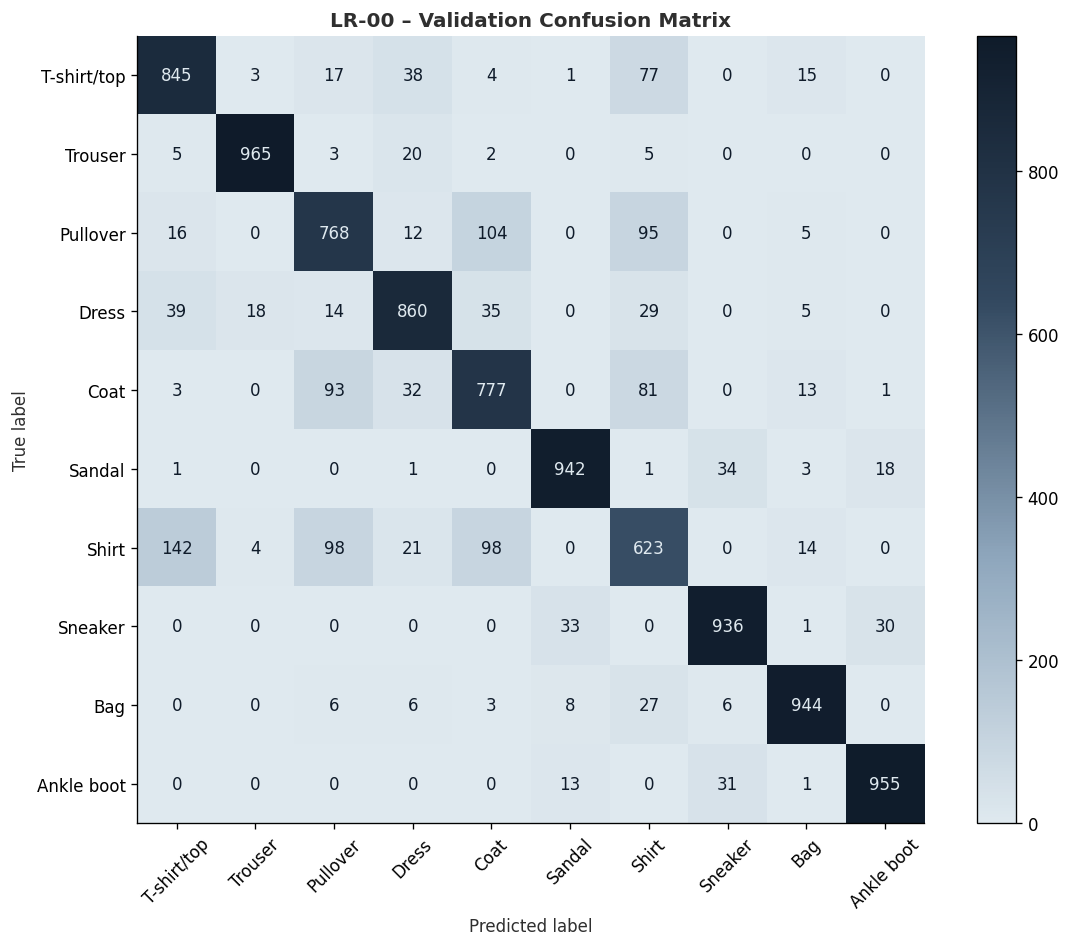

In [33]:
def plot_confusion_matrix(experiment, filename):
    model = experiment["model"]
    X_val = experiment["X_val"]
    y_val = experiment["y_val"]

    predictions = model.predict(X_val)

    matrix = confusion_matrix(
        y_val,
        predictions,
        labels=np.arange(len(CLASS_NAMES)),
    )

    fig, ax = plt.subplots(figsize=(10, 8))

    matrix_display = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=CLASS_NAMES,
    )

    matrix_display.plot(
        ax=ax,
        cmap=BLUE_CMAP,
        values_format="d",
        xticks_rotation=45,
        colorbar=True,
    )

    ax.set_title(f"{experiment['result']['run_id']} – Validation Confusion Matrix")

    fig.tight_layout()
    fig.savefig(FIGURES_DIR / filename, bbox_inches="tight")
    plt.show()

    return matrix


baseline_cm = plot_confusion_matrix(
    baseline,
    "baseline_confusion_matrix.png",
)

### 4.2. Baseline Classification Report

Az összesített accuracy és macro F1-score mellett osztályonként is vizsgáljuk a modell teljesítményét.

A precision, recall és F1-score értékek segítségével azonosíthatók a könnyebben és nehezebben osztályozható ruházati kategóriák.

In [34]:
def get_classification_report(experiment):
    predictions = experiment["model"].predict(experiment["X_val"])

    report = classification_report(
        experiment["y_val"],
        predictions,
        labels=np.arange(len(CLASS_NAMES)),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )

    return pd.DataFrame(report).transpose()


baseline_report = get_classification_report(baseline)

baseline_report.round(4)

,precision,recall,f1-score,support
T-shirt/top,0.8040,0.8450,0.8240,1000.0000
Trouser,0.9747,0.9650,0.9698,1000.0000
Pullover,0.7688,0.7680,0.7684,1000.0000
Dress,0.8687,0.8600,0.8643,1000.0000
Coat,0.7595,0.7770,0.7682,1000.0000
Sandal,0.9448,0.9420,0.9434,1000.0000
Shirt,0.6642,0.6230,0.6429,1000.0000
Sneaker,0.9295,0.9360,0.9327,1000.0000
Bag,0.9431,0.9440,0.9435,1000.0000
Ankle boot,0.9512,0.9550,0.9531,1000.0000


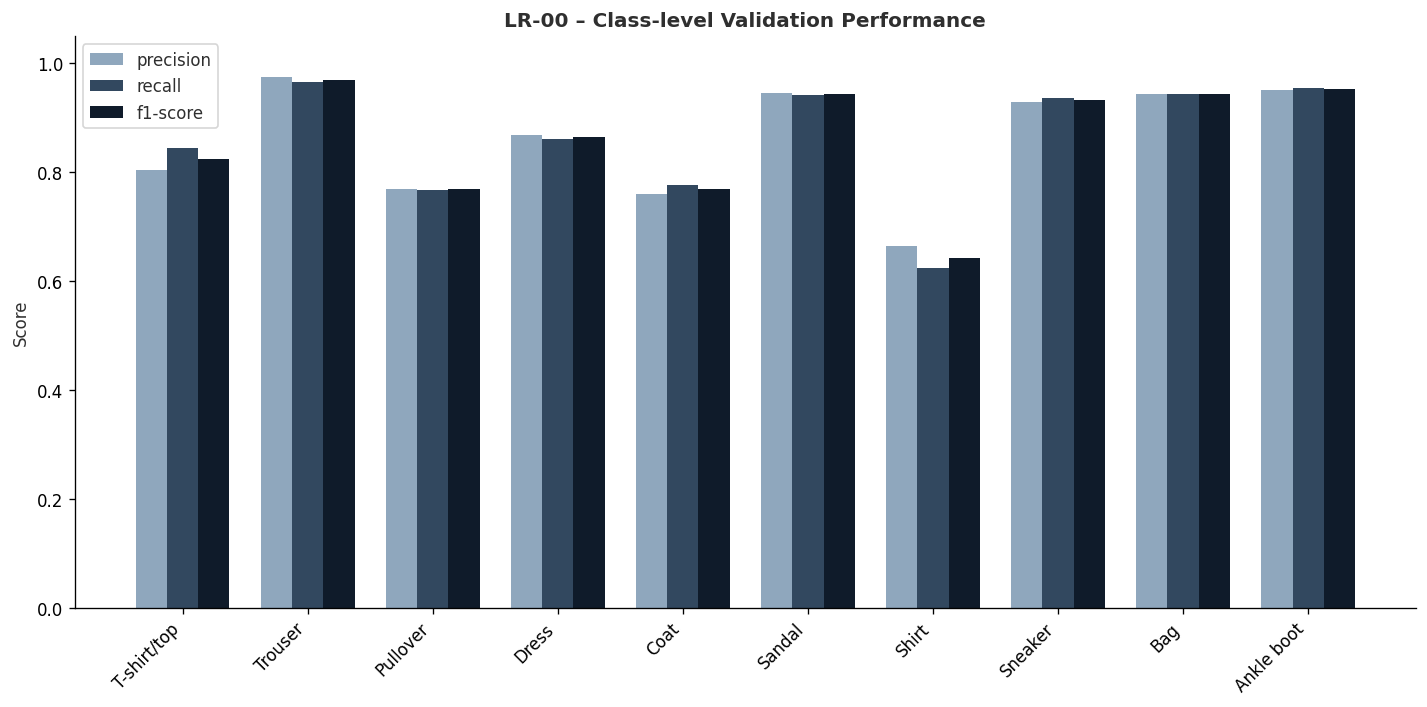

In [35]:
class_metrics = baseline_report.loc[CLASS_NAMES]

fig, ax = plt.subplots(figsize=(12, 6))

positions = np.arange(len(CLASS_NAMES))
width = 0.25

for offset, metric, color in [
    (-width, "precision", PALETTE["blue_3"]),
    (0, "recall", PALETTE["blue_5"]),
    (width, "f1-score", PALETTE["blue_7"]),
]:
    ax.bar(
        positions + offset,
        class_metrics[metric],
        width,
        label=metric,
        color=color,
    )

ax.set_xticks(
    positions,
    CLASS_NAMES,
    rotation=45,
    ha="right",
)

ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("LR-00 – Class-level Validation Performance")
ax.legend()

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "baseline_class_performance.png",
    bbox_inches="tight",
)

plt.show()

### 4.3. Training vs. Validation Performance

A training és validation metrikák összehasonlításával vizsgáljuk a modell általánosítási képességét és az esetleges túlilleszkedés jeleit.

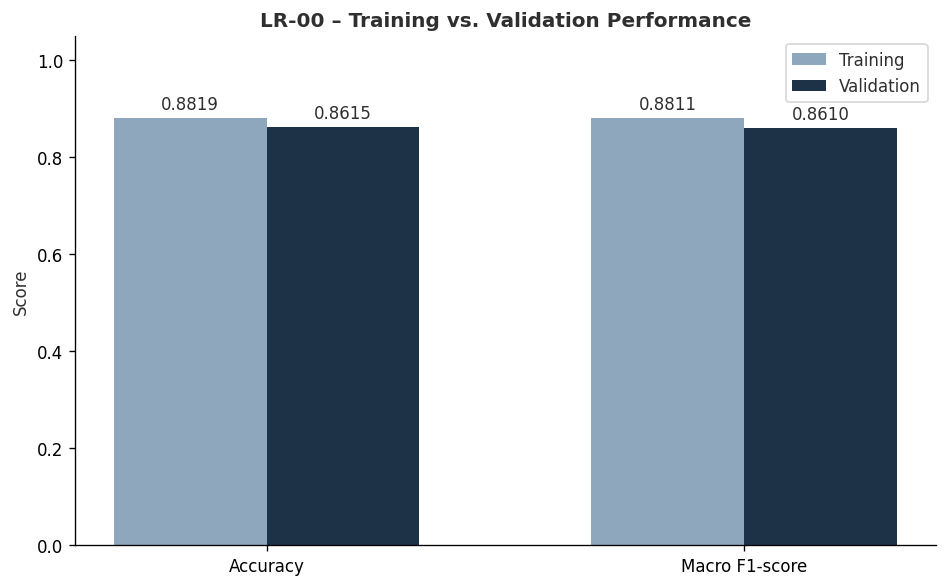

In [36]:
fig, ax = plt.subplots(figsize=(8, 5))

metric_names = ["Accuracy", "Macro F1-score"]
positions = np.arange(len(metric_names))
width = 0.32

train_values = [
    baseline_result["train_accuracy"],
    baseline_result["train_macro_f1"],
]

val_values = [
    baseline_result["val_accuracy"],
    baseline_result["val_macro_f1"],
]

train_bars = ax.bar(
    positions - width / 2,
    train_values,
    width,
    label="Training",
    color=PALETTE["blue_3"],
)

val_bars = ax.bar(
    positions + width / 2,
    val_values,
    width,
    label="Validation",
    color=PALETTE["blue_6"],
)

ax.bar_label(train_bars, fmt="%.4f", padding=3)
ax.bar_label(val_bars, fmt="%.4f", padding=3)

ax.set_xticks(positions, metric_names)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("LR-00 – Training vs. Validation Performance")
ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "baseline_performance.png",
    bbox_inches="tight",
)

plt.show()

### 4.4. Class Weight Visualization

A baseline modell minden osztályhoz 784 elemű súlyvektort tanul meg.

A súlyvektorok 28×28-as mátrixszá alakításával vizualizálható az egyes pixelpozíciók hozzájárulása az osztályok lineáris pontszámaihoz.

A pozitív súlyok növelik, a negatív súlyok csökkentik az adott osztály logitját az adott pixelérték növekedésekor, a többi jellemző változatlansága mellett.

A vizualizáció globális modellparamétereket mutat be, nem egyedi predikciós vagy oksági magyarázatot.

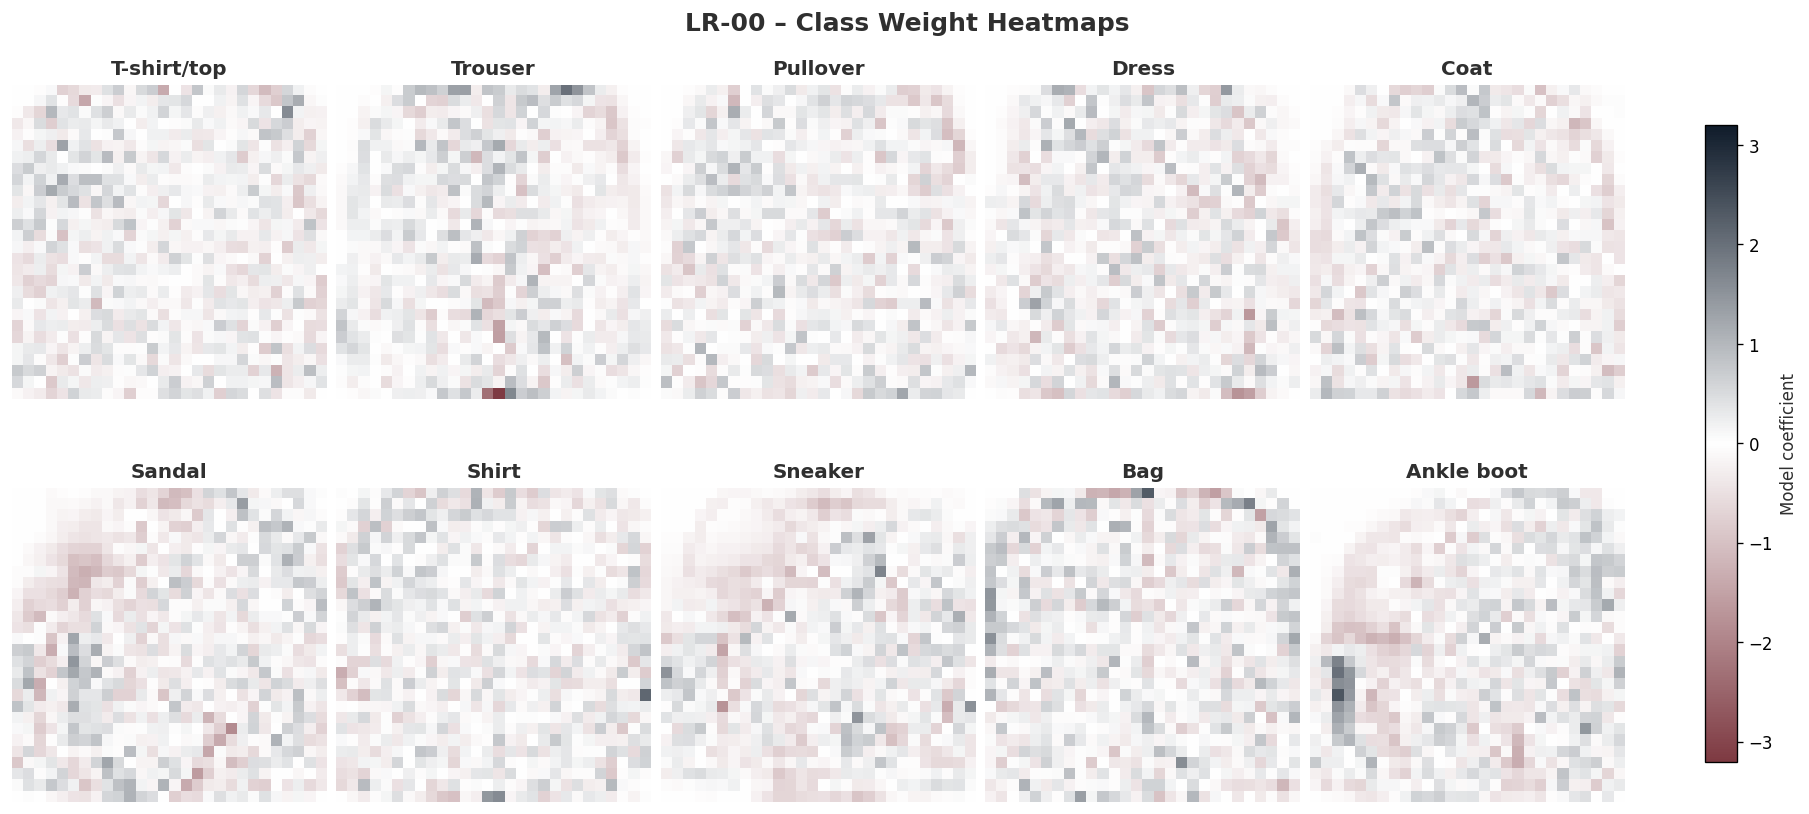

In [37]:
model = baseline["model"]

assert model.coef_.shape == (10, 784)

weights = model.coef_.reshape(10, 28, 28)

max_abs_weight = np.abs(weights).max()

weight_cmap = LinearSegmentedColormap.from_list(
    "project_weights",
    [
        PALETTE["red_dark"],
        PALETTE["white"],
        PALETTE["blue_7"],
    ],
)

fig, axes = plt.subplots(
    2,
    5,
    figsize=(15, 7),
    layout="constrained",
)

for class_id, ax in enumerate(axes.flat):
    image = ax.imshow(
        weights[class_id],
        cmap=weight_cmap,
        vmin=-max_abs_weight,
        vmax=max_abs_weight,
        interpolation="nearest",
    )

    ax.set_title(CLASS_NAMES[class_id])
    ax.axis("off")

fig.colorbar(
    image,
    ax=axes.ravel().tolist(),
    shrink=0.8,
    label="Model coefficient",
)

fig.suptitle(
    "LR-00 – Class Weight Heatmaps",
    fontsize=15,
    fontweight="bold",
)

fig.savefig(
    FIGURES_DIR / "baseline_class_weight_heatmaps.png",
    bbox_inches="tight",
)

plt.show()

### 4.5. EDA and Misclassification Analysis

Az EDA során az osztályonkénti átlagképek cosine similarity elemzése több, vizuálisan hasonló ruházati kategóriapárt azonosított.

A confusion matrix alapján megvizsgáljuk, hogy az azonosított kategóriapárokhoz a modell összes validációs hibájának mekkora hányada köthető.

A tévesztéseket mindkét irányban figyelembe vesszük. Az elemzés célja az EDA megfigyeléseinek és a modell hibamintázatainak összevetése, nem oksági kapcsolat igazolása.

In [38]:
EDA_CLASS_PAIRS = [
    ("T-shirt/top", "Shirt", 0.9489),
    ("Pullover", "Coat", 0.9841),
    ("Pullover", "Shirt", 0.9832),
    ("Coat", "Shirt", 0.9874),
]


def analyze_eda_confusions(matrix):
    class_to_id = {name: idx for idx, name in enumerate(CLASS_NAMES)}

    total_errors = int(matrix.sum() - np.trace(matrix))

    rows = []

    for class_a, class_b, similarity in EDA_CLASS_PAIRS:
        id_a = class_to_id[class_a]
        id_b = class_to_id[class_b]

        errors = int(matrix[id_a, id_b] + matrix[id_b, id_a])

        rows.append(
            {
                "class_a": class_a,
                "class_b": class_b,
                "cosine_similarity": similarity,
                "misclassifications": errors,
                "share_of_total_errors_pct": (
                    errors / total_errors * 100 if total_errors > 0 else 0
                ),
            }
        )

    report = pd.DataFrame(rows)

    selected_errors = int(report["misclassifications"].sum())

    error_share = selected_errors / total_errors * 100 if total_errors > 0 else 0

    return report, total_errors, selected_errors, error_share


(
    baseline_eda_report,
    baseline_total_errors,
    baseline_selected_errors,
    baseline_error_share,
) = analyze_eda_confusions(baseline_cm)

print(f"Total validation errors: {baseline_total_errors}")
print(f"Selected category-pair errors: {baseline_selected_errors}")
print(f"Share of total errors: {baseline_error_share:.2f}%")

baseline_eda_report.round(4)

Total validation errors: 1385
Selected category-pair errors: 788
Share of total errors: 56.90%


,class_a,class_b,cosine_similarity,misclassifications,share_of_total_errors_pct
0,T-shirt/top,Shirt,0.9489,219,15.8123
1,Pullover,Coat,0.9841,197,14.2238
2,Pullover,Shirt,0.9832,193,13.9350
3,Coat,Shirt,0.9874,179,12.9242


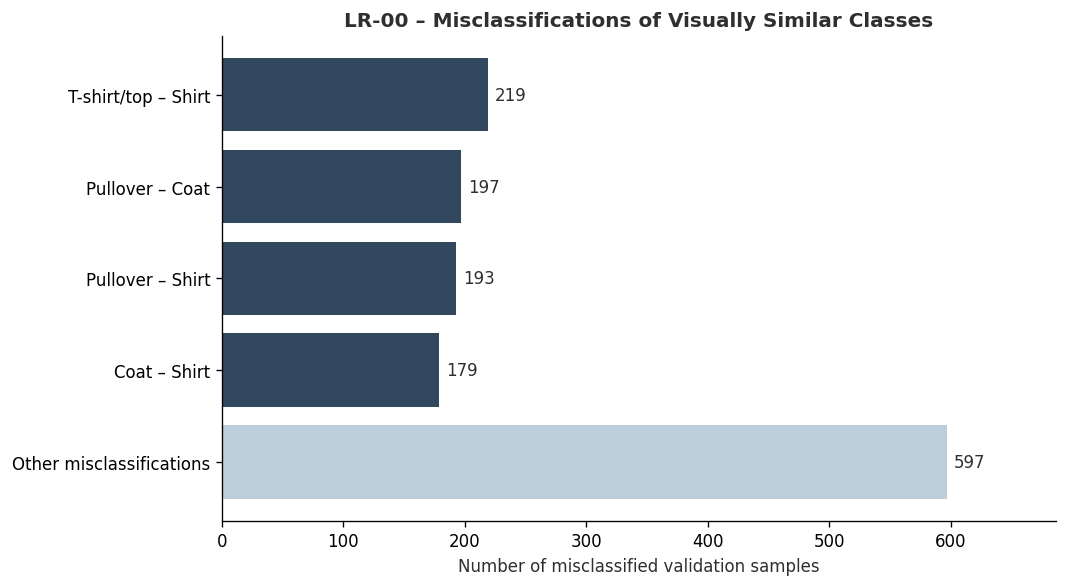

In [39]:
fig, ax = plt.subplots(figsize=(9, 5))

pair_names = (baseline_eda_report["class_a"] + " – " + baseline_eda_report["class_b"]).tolist()

error_counts = baseline_eda_report["misclassifications"].tolist()

pair_names.append("Other misclassifications")

error_counts.append(baseline_total_errors - baseline_selected_errors)

bars = ax.barh(
    pair_names,
    error_counts,
    color=[
        PALETTE["blue_5"],
        PALETTE["blue_5"],
        PALETTE["blue_5"],
        PALETTE["blue_5"],
        PALETTE["blue_2"],
    ],
)

ax.bar_label(bars, padding=4)
ax.invert_yaxis()
ax.set_xlim(0, max(error_counts) * 1.15)
ax.set_xlabel("Number of misclassified validation samples")

ax.set_title("LR-00 – Misclassifications of Visually Similar Classes")

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "baseline_eda_error_analysis.png",
    bbox_inches="tight",
)

plt.show()


### 4.6. Baseline Results and Observations

**Prediktív teljesítmény:** A baseline Logistic Regression modell 88,19%-os training és 86,15%-os validation accuracyt ért el. A validation macro F1-score 86,10%, a validation log loss 0,4062. A mért teljesítmény meghaladja a szakirodalomban szereplő 84,2%-os referenciaértéket, azonban az eltérő kísérleti körülmények miatt a két eredmény közvetlenül nem összehasonlítható.

**Általánosítási képesség:** A training és validation accuracy közötti különbség 2,04 százalékpont, amely viszonylag mérsékelt generalizációs résre utal. A training log loss (0,3356) alacsonyabb a validation log loss értékénél (0,4062).

**Modellkonvergencia:** Az L-BFGS optimalizáló 643 iteráció után sikeresen konvergált, így az 1000 iterációs keret elegendőnek bizonyult. A baseline konfiguráció módosítása nem szükséges.

**Számítási hatékonyság:** Az előfeldolgozás 2,51 másodpercet, a modell tanítása 68,07 másodpercet vett igénybe. A 10 000 validációs mintán mért modellpredikció medián futásideje 0,0411 másodperc. A modell 7850 paramétert tartalmaz, szerializált mérete mindössze 0,0608 MiB.

**Osztályonkénti teljesítmény:** A legmagasabb F1-score értéket a Trouser (96,98%), Ankle boot (95,31%), Bag (94,35%) és Sandal (94,34%) kategóriák érték el. A legnehezebben osztályozható kategória a Shirt, amelynek F1-score értéke 64,29%, recallja 62,30%. A Pullover és Coat kategóriák teljesítménye szintén alacsonyabb az összesített átlagnál.

**Class Weight Heatmaps:** A tanult pixelsúlyok osztályonként eltérő térbeli mintázatokat mutatnak. Egyes kategóriáknál, különösen a lábbelik és a Bag esetében, felismerhetőek a ruhadarabok jellegzetes formáihoz és körvonalaihoz kapcsolódó súlymintázatok. A felsőruházati kategóriák esetében összetettebb, kevésbé egyértelmű mintázatok figyelhetők meg. Az ábrák a modell lineáris együtthatóit szemléltetik, nem oksági magyarázatokat.

**Kapcsolat az EDA eredményeivel:** A modell összesen 1385 validációs mintát osztályozott tévesen. Az EDA során azonosított négy vizuálisan hasonló kategóriapárhoz 788 tévesztés, az összes hiba 56,90%-a kapcsolódik.

| Kategóriapár | Cosine similarity | Tévesztések száma |
|---|---:|---:|
| T-shirt/top – Shirt | 0,9489 | 219 |
| Pullover – Coat | 0,9841 | 197 |
| Pullover – Shirt | 0,9832 | 193 |
| Coat – Shirt | 0,9874 | 179 |
| Összesen | – | 788 |

Az eredmények összhangban állnak az EDA vizuális hasonlóságra vonatkozó megfigyeléseivel, azonban nem igazolnak oksági összefüggést.

**Következő lépések:** A további kísérletek során a regularizáció erősségének, a standardizálásnak, a PCA dimenziócsökkentésnek és a HOG jellemzőkinyerésnek a hatását vizsgáljuk. Célunk a validációs teljesítmény javítása, valamint a prediktív teljesítmény és a számítási költségek közötti kompromisszum feltárása.


## 5. Hiperparaméter-optimalizálás és preprocessing kísérletek

A baseline modellre építve kontrollált optimalizálási kísérleteket végzünk. Az egyedi kísérletekben egy tényezőt változtatunk, miközben a többi baseline paraméter változatlan marad.

A kísérletek három fő csoportja:

- Regularizáció erősségének vizsgálata.
- Alternatív adatreprezentációk vizsgálata.
- A legígéretesebb konfigurációk kombinálása.

Minden futtatás azonos training és validation halmazt, valamint random seedet használ. A modellválasztás kizárólag a validációs eredmények alapján történik.

| Run ID | Kísérlet |
|---|---|
| LR-01 | C=0.01 |
| LR-02 | C=0.1 |
| LR-03 | C=10.0 |
| LR-04 | StandardScaler |
| LR-05 | PCA, 84 komponens |
| LR-06 | PCA, 187 komponens |
| LR-07 | HOG |
| LR-08+ | Kombinált optimalizálás |

Az eredetileg tervezett 100 és 200 PCA-komponens helyett az EDA eredményei alapján 84 és 187 komponenst alkalmazunk, amelyek legalább 90%, illetve 95% training variancia megőrzését biztosítják.

In [43]:
baseline_model = joblib.load(ARTIFACTS_DIR / "LR-00" / "model.joblib")

baseline_preprocessor = joblib.load(ARTIFACTS_DIR / "LR-00" / "preprocessor.joblib")

datasets, _ = build_ml_datasets(
    train_dataset,
    test_dataset,
    train_indices,
    val_indices,
    seed=SEED,
)

for split in ("train", "val"):
    X, y = datasets[split]

    metrics = evaluate_model(baseline_model, X, y)

    baseline_result[f"{split}_macro_precision"] = metrics["macro_precision"]
    baseline_result[f"{split}_macro_recall"] = metrics["macro_recall"]

save_experiment_result(baseline_result)

del datasets, X, y

print("Baseline metrics successfully updated.")

Baseline metrics successfully updated.


In [44]:
def show_experiment_results(run_ids=None):
    results = pd.read_csv(RESULTS_PATH)

    if run_ids is not None:
        results = results[results["run_id"].isin(run_ids)]

    columns = [
        "run_id",
        "description",
        "n_features",
        "train_accuracy",
        "val_accuracy",
        "val_macro_precision",
        "val_macro_recall",
        "val_macro_f1",
        "val_log_loss",
        "accuracy_gap",
        "preprocessing_time_s",
        "training_time_s",
        "inference_time_s",
        "model_size_mib",
        "n_iter",
        "converged",
    ]

    return results[columns].sort_values("run_id").reset_index(drop=True).round(6)


show_experiment_results()

,run_id,description,n_features,train_accuracy,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_log_loss,accuracy_gap,preprocessing_time_s,training_time_s,inference_time_s,model_size_mib,n_iter,converged
0,LR-00,Baseline,784,0.8819,0.8615,0.860849,0.8615,0.861041,0.406229,0.0204,2.513707,68.065178,0.041121,0.060767,643,True


### 5.1. Regularization Experiments

A regularizáció erősségének hatását a C hiperparaméter változtatásával vizsgáljuk.

- C=0.01: erős regularizáció, kisebb súlyok, potenciális underfitting.
- C=0.1: erősebb regularizáció a baseline-hoz képest, potenciálisan jobb általánosítás.
- C=1.0: baseline konfiguráció.
- C=10.0: gyengébb regularizáció, jobb illeszkedés, potenciális overfitting.

Minden futtatás L2 regularizációt, L-BFGS optimalizálót és nyers pixelreprezentációt használ.

In [45]:
lr_01 = run_experiment(
    run_id="LR-01",
    config={
        **BASELINE_CONFIG,
        "C": 0.01,
    },
    description="Strong L2 regularization (C=0.01)",
)

show_experiment_results(["LR-00", "LR-01"])


Starting experiment: LR-01
--------------------------------------------------
Training shape:   (50000, 784)
Validation shape: (10000, 784)
Preprocessing time: 2.62 s

Training model...
Training time: 23.77 s
Converged: True
Iterations: [222]

Experiment completed.
Training accuracy:   0.8558
Validation accuracy: 0.8580
Validation macro F1: 0.8572
Validation log loss: 0.4247
Parameter count:     7,850
Results saved to: c:\Users\aszen\Desktop\ÓBUDAI MSC\03_2026-2027-1\03_DL\00_Feleves feladat\KÓDOK\DLProject_FashionMNIST\results\experiments\logistic_regression_experiments.csv


,run_id,description,n_features,train_accuracy,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_log_loss,accuracy_gap,preprocessing_time_s,training_time_s,inference_time_s,model_size_mib,n_iter,converged
0,LR-00,Baseline,784,0.88190,0.8615,0.860849,0.8615,0.861041,0.406229,0.02040,2.513707,68.065178,0.041121,0.060767,643,True
1,LR-01,Strong L2 regularization (C=0.01),784,0.85584,0.8580,0.857080,0.8580,0.857205,0.424743,-0.00216,2.616325,23.772649,0.039037,0.060767,222,True


In [46]:
lr_02 = run_experiment(
    run_id="LR-02",
    config={
        **BASELINE_CONFIG,
        "C": 0.1,
    },
    description="Moderate L2 regularization (C=0.1)",
)

show_experiment_results(["LR-00", "LR-01", "LR-02"])


Starting experiment: LR-02
--------------------------------------------------
Training shape:   (50000, 784)
Validation shape: (10000, 784)
Preprocessing time: 2.80 s

Training model...
Training time: 29.52 s
Converged: True
Iterations: [306]

Experiment completed.
Training accuracy:   0.8726
Validation accuracy: 0.8646
Validation macro F1: 0.8640
Validation log loss: 0.3894
Parameter count:     7,850
Results saved to: c:\Users\aszen\Desktop\ÓBUDAI MSC\03_2026-2027-1\03_DL\00_Feleves feladat\KÓDOK\DLProject_FashionMNIST\results\experiments\logistic_regression_experiments.csv


,run_id,description,n_features,train_accuracy,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_log_loss,accuracy_gap,preprocessing_time_s,training_time_s,inference_time_s,model_size_mib,n_iter,converged
0,LR-00,Baseline,784,0.88190,0.8615,0.860849,0.8615,0.861041,0.406229,0.02040,2.513707,68.065178,0.041121,0.060767,643,True
1,LR-01,Strong L2 regularization (C=0.01),784,0.85584,0.8580,0.857080,0.8580,0.857205,0.424743,-0.00216,2.616325,23.772649,0.039037,0.060767,222,True
2,LR-02,Moderate L2 regularization (C=0.1),784,0.87256,0.8646,0.863780,0.8646,0.863954,0.389429,0.00796,2.803360,29.519786,0.035901,0.060767,306,True


In [47]:
lr_03 = run_experiment(
    run_id="LR-03",
    config={
        **BASELINE_CONFIG,
        "C": 10.0,
    },
    description="Weak L2 regularization (C=10.0)",
)

show_experiment_results(["LR-00", "LR-01", "LR-02", "LR-03"])


Starting experiment: LR-03
--------------------------------------------------
Training shape:   (50000, 784)
Validation shape: (10000, 784)
Preprocessing time: 2.47 s

Training model...
Training time: 97.59 s
Converged: False
Iterations: [1000]
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression

Experiment completed.
Training accuracy:   0.8855
Validation accuracy: 0.8563
Validation macro F1: 0.8557
Validation log loss: 0.4350
Parameter count:     7,850
Results saved to: c:\Users\aszen\Desktop\ÓBUDAI MSC\03_2026-2027-1\03_DL\00_Feleves feladat\KÓDOK\DLProject_FashionMNIST\results\experiments\logistic_regression_experiments.csv


,run_id,description,n_features,train_accuracy,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_log_loss,accuracy_gap,preprocessing_time_s,training_time_s,inference_time_s,model_size_mib,n_iter,converged
0,LR-00,Baseline,784,0.88190,0.8615,0.860849,0.8615,0.861041,0.406229,0.02040,2.513707,68.065178,0.041121,0.060767,643,True
1,LR-01,Strong L2 regularization (C=0.01),784,0.85584,0.8580,0.857080,0.8580,0.857205,0.424743,-0.00216,2.616325,23.772649,0.039037,0.060767,222,True
2,LR-02,Moderate L2 regularization (C=0.1),784,0.87256,0.8646,0.863780,0.8646,0.863954,0.389429,0.00796,2.803360,29.519786,0.035901,0.060767,306,True
3,LR-03,Weak L2 regularization (C=10.0),784,0.88554,0.8563,0.855313,0.8563,0.855673,0.435033,0.02924,2.466850,97.592810,0.036641,0.060767,1000,False


#### LR-03B – Convergence Control Experiment

Az LR-03 konfiguráció C=10.0 mellett nem konvergált az 1000 iterációs kereten belül. Annak vizsgálatára, hogy a konvergenciaprobléma az iterációs limitből ered-e, azonos konfigurációval, de magasabb max_iter értékkel kontrollfuttatást végzünk.

Kizárólag a max_iter paramétert módosítjuk 1000-ről 3000-re.

In [48]:
lr_03b = run_experiment(
    run_id="LR-03B",
    config={
        **BASELINE_CONFIG,
        "C": 10.0,
        "max_iter": 3000,
    },
    description="Weak L2 regularization convergence control (C=10.0)",
)

show_experiment_results(["LR-00", "LR-03", "LR-03B"])


Starting experiment: LR-03B
--------------------------------------------------
Training shape:   (50000, 784)
Validation shape: (10000, 784)
Preprocessing time: 2.48 s

Training model...
Training time: 115.00 s
Converged: True
Iterations: [1204]

Experiment completed.
Training accuracy:   0.8860
Validation accuracy: 0.8565
Validation macro F1: 0.8559
Validation log loss: 0.4355
Parameter count:     7,850
Results saved to: c:\Users\aszen\Desktop\ÓBUDAI MSC\03_2026-2027-1\03_DL\00_Feleves feladat\KÓDOK\DLProject_FashionMNIST\results\experiments\logistic_regression_experiments.csv


,run_id,description,n_features,train_accuracy,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_log_loss,accuracy_gap,preprocessing_time_s,training_time_s,inference_time_s,model_size_mib,n_iter,converged
0,LR-00,Baseline,784,0.88190,0.8615,0.860849,0.8615,0.861041,0.406229,0.02040,2.513707,68.065178,0.041121,0.060767,643,True
1,LR-03,Weak L2 regularization (C=10.0),784,0.88554,0.8563,0.855313,0.8563,0.855673,0.435033,0.02924,2.466850,97.592810,0.036641,0.060767,1000,False
2,LR-03B,Weak L2 regularization convergence control (C=...,784,0.88602,0.8565,0.855603,0.8565,0.855945,0.435521,0.02952,2.476171,114.995831,0.036139,0.060767,1204,True


In [49]:
regularization_results = show_experiment_results(["LR-00", "LR-01", "LR-02", "LR-03", "LR-03B"])

regularization_results.sort_values(
    "val_accuracy",
    ascending=False,
)

,run_id,description,n_features,train_accuracy,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_log_loss,accuracy_gap,preprocessing_time_s,training_time_s,inference_time_s,model_size_mib,n_iter,converged
2,LR-02,Moderate L2 regularization (C=0.1),784,0.87256,0.8646,0.863780,0.8646,0.863954,0.389429,0.00796,2.803360,29.519786,0.035901,0.060767,306,True
0,LR-00,Baseline,784,0.88190,0.8615,0.860849,0.8615,0.861041,0.406229,0.02040,2.513707,68.065178,0.041121,0.060767,643,True
1,LR-01,Strong L2 regularization (C=0.01),784,0.85584,0.8580,0.857080,0.8580,0.857205,0.424743,-0.00216,2.616325,23.772649,0.039037,0.060767,222,True
4,LR-03B,Weak L2 regularization convergence control (C=...,784,0.88602,0.8565,0.855603,0.8565,0.855945,0.435521,0.02952,2.476171,114.995831,0.036139,0.060767,1204,True
3,LR-03,Weak L2 regularization (C=10.0),784,0.88554,0.8563,0.855313,0.8563,0.855673,0.435033,0.02924,2.466850,97.592810,0.036641,0.060767,1000,False



#### Regularization Experiment Observations

**Prediktív teljesítmény:** A regularizációs kísérletek közül az LR-02 (C=0.1) biztosította a legjobb validációs teljesítményt, 86,46%-os accuracy és 86,40%-os macro F1-score mellett. Ez a baseline-hoz képest 0,31 százalékpontos accuracy javulást jelent. A validation log loss 0,4062-ről 0,3894-re csökkent.

**Általánosítási képesség:** Az LR-02 training–validation accuracy gapje 0,80 százalékpont, szemben a baseline 2,04 százalékpontos különbségével. Az erősebb regularizáció tehát a vizsgált konfigurációban kedvezőbb általánosítási teljesítményt eredményezett.

**Erős regularizáció (LR-01):** A C=0.01 konfiguráció training és validation accuracyje egyaránt alacsonyabb a baseline értékeinél. Ez összhangban áll a túl erős regularizáció miatti underfitting hipotézisével. A modell ugyanakkor mindössze 222 iteráció alatt konvergált.

**Gyenge regularizáció (LR-03 és LR-03B):** A C=10.0 konfiguráció magasabb training accuracyt, de alacsonyabb validation accuracyt és nagyobb generalizációs rést eredményezett. Ez a túlillesztés erősödésére utal. Az LR-03 nem konvergált az 1000 iterációs kereten belül, ezért az LR-03B kontrollfuttatásban 3000-re növeltük a max_iter értékét. A modell 1204 iteráció után sikeresen konvergált, azonban a validation accuracy mindössze 0,02 százalékponttal javult.

**Számítási hatékonyság:** Az LR-02 tanítási ideje 29,52 másodperc, amely 56,6%-os csökkenést jelent a baseline 68,07 másodperces futásidejéhez képest. A regularizációs kísérletek során a modell paraméterszáma és szerializált mérete változatlan maradt.

**Következtetés:** A vizsgált C értékek közül a C=0.1 biztosította a legkedvezőbb pontosság–számítási költség kompromisszumot. A további kombinált optimalizálási kísérleteknél ezt az értéket kiemelten vizsgáljuk.


### 5.2. Preprocessing Experiments

A különböző adatreprezentációk hatását azonos baseline modellhiperparaméterek mellett vizsgáljuk.

| Run ID | Reprezentáció | Jellemzők száma |
|---|---|---:|
| LR-00 | Nyers pixelvektor | 784 |
| LR-04 | StandardScaler | 784 |
| LR-05 | PCA, 90% variancia | 84 |
| LR-06 | PCA, 95% variancia | 187 |
| LR-07 | HOG | 1296 |

A StandardScaler és PCA illesztése kizárólag a training halmazon történik. A validation és test adatokra az illesztett transzformáció kerül alkalmazásra.

A prediktív teljesítmény mellett az előfeldolgozás időigényét, a tanítási időt, a modellméretet és az inferenciaidőt is összehasonlítjuk.

In [50]:
lr_04 = run_experiment(
    run_id="LR-04",
    config={
        **BASELINE_CONFIG,
        "standardize": True,
    },
    description="Standardized pixel representation",
)

show_experiment_results(["LR-00", "LR-04"])


Starting experiment: LR-04
--------------------------------------------------
Training shape:   (50000, 784)
Validation shape: (10000, 784)
Preprocessing time: 3.42 s

Training model...
Training time: 94.14 s
Converged: False
Iterations: [1000]
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression

Experiment completed.
Training accuracy:   0.8879
Validation accuracy: 0.8549
Validation macro F1: 0.8543
Validation log loss: 0.4744
Parameter count:     7,850
Results saved to: c:\Users\aszen\Desktop\ÓBUDAI MSC\03_2026-2027-1\03_DL\00_Feleves feladat\KÓDOK\DLProject_FashionMNIST\results\experiments\logistic_regression_experiments.csv


,run_id,description,n_features,train_accuracy,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_log_loss,accuracy_gap,preprocessing_time_s,training_time_s,inference_time_s,model_size_mib,n_iter,converged
0,LR-00,Baseline,784,0.88190,0.8615,0.860849,0.8615,0.861041,0.406229,0.02040,2.513707,68.065178,0.041121,0.060767,643,True
1,LR-04,Standardized pixel representation,784,0.88788,0.8549,0.853943,0.8549,0.854301,0.474424,0.03298,3.420459,94.138124,0.035529,0.060767,1000,False


#### LR-04B – StandardScaler Convergence Control Experiment

Az LR-04 konfiguráció standardizált bemeneti jellemzők mellett nem konvergált az 1000 iterációs kereten belül.

A konvergenciaprobléma vizsgálatához azonos konfigurációval, de 3000-es max_iter értékkel kontrollfuttatást végzünk.

Kizárólag az iterációs limitet módosítjuk.

In [51]:
lr_04b = run_experiment(
    run_id="LR-04B",
    config={
        **BASELINE_CONFIG,
        "standardize": True,
        "max_iter": 3000,
    },
    description="StandardScaler convergence control (max_iter=3000)",
)

show_experiment_results(["LR-00", "LR-04", "LR-04B"])


Starting experiment: LR-04B
--------------------------------------------------
Training shape:   (50000, 784)
Validation shape: (10000, 784)
Preprocessing time: 3.00 s

Training model...
Training time: 105.13 s
Converged: True
Iterations: [1072]

Experiment completed.
Training accuracy:   0.8880
Validation accuracy: 0.8545
Validation macro F1: 0.8540
Validation log loss: 0.4736
Parameter count:     7,850
Results saved to: c:\Users\aszen\Desktop\ÓBUDAI MSC\03_2026-2027-1\03_DL\00_Feleves feladat\KÓDOK\DLProject_FashionMNIST\results\experiments\logistic_regression_experiments.csv


,run_id,description,n_features,train_accuracy,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_log_loss,accuracy_gap,preprocessing_time_s,training_time_s,inference_time_s,model_size_mib,n_iter,converged
0,LR-00,Baseline,784,0.88190,0.8615,0.860849,0.8615,0.861041,0.406229,0.02040,2.513707,68.065178,0.041121,0.060767,643,True
1,LR-04,Standardized pixel representation,784,0.88788,0.8549,0.853943,0.8549,0.854301,0.474424,0.03298,3.420459,94.138124,0.035529,0.060767,1000,False
2,LR-04B,StandardScaler convergence control (max_iter=3...,784,0.88804,0.8545,0.853641,0.8545,0.853956,0.473632,0.03354,2.995229,105.131694,0.039834,0.060767,1072,True


#### StandardScaler Experiment Observations

A StandardScaler alkalmazása mellett az LR-04 konfiguráció 85,49%-os validation accuracyt ért el, azonban nem konvergált az 1000 iterációs kereten belül.

Az LR-04B kontrollfuttatásban a modell 1072 iteráció után sikeresen konvergált. A validation accuracy 85,45%, a macro F1-score 85,40%, a validation log loss pedig 0,4736 lett.

A magasabb iterációs limit megoldotta a konvergenciaproblémát, de nem eredményezett prediktív teljesítményjavulást.

A baseline-hoz képest a standardizált modell magasabb training accuracyt, alacsonyabb validation accuracyt és nagyobb generalizációs rést mutatott. A vizsgált konfigurációban tehát a standardizálás nem javította az általánosítási képességet, és növelte a tanítási időt.

A standardizálás megváltoztatja a jellemzők skáláját és ezáltal a regularizáció hatását is, ezért más C érték mellett eltérő eredmény lehetséges.

#### PCA Dimensionality Reduction Experiments

Az EDA cumulative explained variance elemzése alapján két PCA konfigurációt vizsgálunk:

- 84 komponens: 90%-os varianciamegőrzési célérték.
- 187 komponens: 95%-os varianciamegőrzési célérték.

Mindkét futtatás a baseline modellhiperparamétereket használja. A PCA illesztése kizárólag a training halmazon történik.

A kísérletek célja a dimenziócsökkentés prediktív teljesítményre, modellméretre és számítási hatékonyságra gyakorolt hatásának vizsgálata.

In [53]:
lr_05 = run_experiment(
    run_id="LR-05",
    config={
        **BASELINE_CONFIG,
        "pca_components": 84,
    },
    description="PCA with 84 components (90% variance target)",
)

show_experiment_results(["LR-00", "LR-02", "LR-05"])


Starting experiment: LR-05
--------------------------------------------------
Training shape:   (50000, 84)
Validation shape: (10000, 84)
Preprocessing time: 2.74 s

Training model...
Training time: 8.13 s
Converged: True
Iterations: [444]

Experiment completed.
Training accuracy:   0.8526
Validation accuracy: 0.8540
Validation macro F1: 0.8533
Validation log loss: 0.4123
Parameter count:     850
Results saved to: c:\Users\aszen\Desktop\ÓBUDAI MSC\03_2026-2027-1\03_DL\00_Feleves feladat\KÓDOK\DLProject_FashionMNIST\results\experiments\logistic_regression_experiments.csv


,run_id,description,n_features,train_accuracy,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_log_loss,accuracy_gap,preprocessing_time_s,training_time_s,inference_time_s,model_size_mib,n_iter,converged
0,LR-00,Baseline,784,0.88190,0.8615,0.860849,0.8615,0.861041,0.406229,0.02040,2.513707,68.065178,0.041121,0.060767,643,True
1,LR-02,Moderate L2 regularization (C=0.1),784,0.87256,0.8646,0.863780,0.8646,0.863954,0.389429,0.00796,2.803360,29.519786,0.035901,0.060767,306,True
2,LR-05,PCA with 84 components (90% variance target),84,0.85258,0.8540,0.853063,0.8540,0.853283,0.412250,-0.00142,2.735757,8.129798,0.002915,0.007361,444,True


In [54]:
lr_06 = run_experiment(
    run_id="LR-06",
    config={
        **BASELINE_CONFIG,
        "pca_components": 187,
    },
    description="PCA with 187 components (95% variance target)",
)

show_experiment_results(["LR-00", "LR-02", "LR-05", "LR-06"])


Starting experiment: LR-06
--------------------------------------------------
Training shape:   (50000, 187)
Validation shape: (10000, 187)
Preprocessing time: 2.82 s

Training model...
Training time: 14.27 s
Converged: True
Iterations: [433]

Experiment completed.
Training accuracy:   0.8648
Validation accuracy: 0.8654
Validation macro F1: 0.8648
Validation log loss: 0.3926
Parameter count:     1,880
Results saved to: c:\Users\aszen\Desktop\ÓBUDAI MSC\03_2026-2027-1\03_DL\00_Feleves feladat\KÓDOK\DLProject_FashionMNIST\results\experiments\logistic_regression_experiments.csv


,run_id,description,n_features,train_accuracy,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_log_loss,accuracy_gap,preprocessing_time_s,training_time_s,inference_time_s,model_size_mib,n_iter,converged
0,LR-00,Baseline,784,0.88190,0.8615,0.860849,0.8615,0.861041,0.406229,0.02040,2.513707,68.065178,0.041121,0.060767,643,True
1,LR-02,Moderate L2 regularization (C=0.1),784,0.87256,0.8646,0.863780,0.8646,0.863954,0.389429,0.00796,2.803360,29.519786,0.035901,0.060767,306,True
2,LR-05,PCA with 84 components (90% variance target),84,0.85258,0.8540,0.853063,0.8540,0.853283,0.412250,-0.00142,2.735757,8.129798,0.002915,0.007361,444,True
3,LR-06,PCA with 187 components (95% variance target),187,0.86484,0.8654,0.864621,0.8654,0.864805,0.392648,-0.00056,2.821692,14.271054,0.011734,0.015220,433,True


In [55]:
pca_results = []

for experiment in (lr_05, lr_06):
    pca = experiment["preprocessor"].named_steps["pca"]

    explained_variance = pca.explained_variance_ratio_.sum()

    pca_results.append(
        {
            "run_id": experiment["result"]["run_id"],
            "n_components": pca.n_components_,
            "explained_variance": explained_variance,
            "explained_variance_pct": explained_variance * 100,
        }
    )

pd.DataFrame(pca_results).round(4)

,run_id,n_components,explained_variance,explained_variance_pct
0,LR-05,84,0.9006,90.055603
1,LR-06,187,0.9500,95.000397


#### HOG Feature Representation Experiment

A HOG jellemzőkinyerési módszer a képek lokális gradiensirányait és intenzitásváltozásait reprezentálja.

A közös ML preprocessing pipeline segítségével a 784 elemű pixelvektorok helyett 1296 elemű HOG jellemzővektorokat használunk.

Hipotézisünk szerint a lokális körvonalinformációk javíthatják a lineáris osztályozó prediktív teljesítményét, ugyanakkor növelhetik az előfeldolgozás számítási költségét.

In [56]:
lr_07 = run_experiment(
    run_id="LR-07",
    config={
        **BASELINE_CONFIG,
        "use_hog": True,
    },
    description="Histogram of Oriented Gradients features",
)

show_experiment_results(["LR-00", "LR-02", "LR-05", "LR-06", "LR-07"])


Starting experiment: LR-07
--------------------------------------------------
Training shape:   (50000, 1296)
Validation shape: (10000, 1296)
Preprocessing time: 44.57 s

Training model...
Training time: 38.23 s
Converged: True
Iterations: [257]

Experiment completed.
Training accuracy:   0.9192
Validation accuracy: 0.8867
Validation macro F1: 0.8866
Validation log loss: 0.3096
Parameter count:     12,970
Results saved to: c:\Users\aszen\Desktop\ÓBUDAI MSC\03_2026-2027-1\03_DL\00_Feleves feladat\KÓDOK\DLProject_FashionMNIST\results\experiments\logistic_regression_experiments.csv


,run_id,description,n_features,train_accuracy,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_log_loss,accuracy_gap,preprocessing_time_s,training_time_s,inference_time_s,model_size_mib,n_iter,converged
0,LR-00,Baseline,784,0.88190,0.8615,0.860849,0.8615,0.861041,0.406229,0.02040,2.513707,68.065178,0.041121,0.060767,643,True
1,LR-02,Moderate L2 regularization (C=0.1),784,0.87256,0.8646,0.863780,0.8646,0.863954,0.389429,0.00796,2.803360,29.519786,0.035901,0.060767,306,True
2,LR-05,PCA with 84 components (90% variance target),84,0.85258,0.8540,0.853063,0.8540,0.853283,0.412250,-0.00142,2.735757,8.129798,0.002915,0.007361,444,True
3,LR-06,PCA with 187 components (95% variance target),187,0.86484,0.8654,0.864621,0.8654,0.864805,0.392648,-0.00056,2.821692,14.271054,0.011734,0.015220,433,True
4,LR-07,Histogram of Oriented Gradients features,1296,0.91922,0.8867,0.886610,0.8867,0.886636,0.309564,0.03252,44.571044,38.226203,0.060133,0.099830,257,True


#### Preprocessing Experiment Observations

**PCA dimenziócsökkentés:** Az LR-05 konfiguráció 84 komponenssel a training variancia 90,0556%-át őrizte meg, és 85,40%-os validation accuracyt ért el. Az LR-06 konfiguráció 187 komponenssel a variancia 95,0004%-át őrizte meg, miközben 86,54%-os validation accuracyt biztosított.

Az LR-06 a baseline-hoz képest 0,39 százalékpontos pontosságjavulást eredményezett, miközben a modell tanítási ideje 68,07 másodpercről 14,27 másodpercre csökkent.

A PCA jelentősen csökkentette a modell paraméterszámát és szerializált méretét. A teljes pipeline tárolási költségének értékelésekor azonban az illesztett PCA objektum méretét is figyelembe kell venni.

**HOG jellemzőkinyerés:** Az LR-07 konfiguráció érte el az eddigi legjobb validációs teljesítményt, 88,67%-os accuracy és 88,66%-os macro F1-score mellett. Ez a baseline-hoz képest 2,52 százalékpontos javulás.

A validation log loss 0,4062-ről 0,3096-ra csökkent. A lokális gradiensinformációk reprezentációja tehát a vizsgált konfigurációban kedvezően befolyásolta a lineáris osztályozó teljesítményét.

**Általánosítási képesség:** A HOG modell training–validation accuracy gapje 3,25 százalékpont, amely nagyobb a baseline 2,04 százalékpontos különbségénél. Ez indokolja a regularizáció erősségének további vizsgálatát.

**Számítási hatékonyság:** A HOG előfeldolgozása 44,57 másodpercet vett igénybe, szemben a baseline 2,51 másodperces preprocessing idejével. A modell tanítási ideje ugyanakkor 38,23 másodpercre csökkent. A jobb prediktív teljesítmény tehát előfeldolgozási többletköltséggel jár.

**Kapcsolat a Random Forest eredményeivel:** A Random Forest esetében a PCA és a HOG reprezentációk egyaránt rontották a validációs teljesítményt. Ezzel szemben a Logistic Regression esetében a 187 komponenses PCA és különösen a HOG javította azt. Az eredmények arra utalnak, hogy az alternatív adatreprezentációk hatása modellfüggő.

In [57]:
experiment_results = pd.read_csv(RESULTS_PATH)

ranked_results = experiment_results.sort_values(
    by=[
        "val_accuracy",
        "val_macro_f1",
        "model_size_bytes",
    ],
    ascending=[False, False, True],
).reset_index(drop=True)

ranked_results.insert(
    0,
    "rank",
    np.arange(1, len(ranked_results) + 1),
)

ranked_results[
    [
        "rank",
        "run_id",
        "description",
        "n_features",
        "train_accuracy",
        "val_accuracy",
        "val_macro_precision",
        "val_macro_recall",
        "val_macro_f1",
        "val_log_loss",
        "accuracy_gap",
        "training_time_s",
        "model_size_mib",
        "n_iter",
        "converged",
    ]
].round(6)

,rank,run_id,description,n_features,train_accuracy,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_log_loss,accuracy_gap,training_time_s,model_size_mib,n_iter,converged
0,1,LR-07,Histogram of Oriented Gradients features,1296,0.91922,0.8867,0.886610,0.8867,0.886636,0.309564,0.03252,38.226203,0.099830,257,True
1,2,LR-06,PCA with 187 components (95% variance target),187,0.86484,0.8654,0.864621,0.8654,0.864805,0.392648,-0.00056,14.271054,0.015220,433,True
2,3,LR-02,Moderate L2 regularization (C=0.1),784,0.87256,0.8646,0.863780,0.8646,0.863954,0.389429,0.00796,29.519786,0.060767,306,True
3,4,LR-00,Baseline,784,0.88190,0.8615,0.860849,0.8615,0.861041,0.406229,0.02040,68.065178,0.060767,643,True
4,5,LR-01,Strong L2 regularization (C=0.01),784,0.85584,0.8580,0.857080,0.8580,0.857205,0.424743,-0.00216,23.772649,0.060767,222,True
5,6,LR-03B,Weak L2 regularization convergence control (C=...,784,0.88602,0.8565,0.855603,0.8565,0.855945,0.435521,0.02952,114.995831,0.060767,1204,True
6,7,LR-03,Weak L2 regularization (C=10.0),784,0.88554,0.8563,0.855313,0.8563,0.855673,0.435033,0.02924,97.592810,0.060767,1000,False
7,8,LR-04,Standardized pixel representation,784,0.88788,0.8549,0.853943,0.8549,0.854301,0.474424,0.03298,94.138124,0.060767,1000,False
8,9,LR-04B,StandardScaler convergence control (max_iter=3...,784,0.88804,0.8545,0.853641,0.8545,0.853956,0.473632,0.03354,105.131694,0.060767,1072,True
9,10,LR-05,PCA with 84 components (90% variance target),84,0.85258,0.8540,0.853063,0.8540,0.853283,0.412250,-0.00142,8.129798,0.007361,444,True


### 5.3. Combined Optimization Experiments

Az egyedi preprocessing kísérletek során a HOG reprezentáció biztosította a legjobb validációs teljesítményt.

A további kísérletekben a HOG jellemzőkinyerést kombináljuk a korábban vizsgált regularizációs konfigurációkkal.

| Run ID | HOG | C |
|---|---|---:|
| LR-07 | True | 1.0 |
| LR-08 | True | 0.01 |
| LR-09 | True | 0.1 |
| LR-10 | True | 10.0 |

A kísérletek célja annak vizsgálata, hogy a regularizáció módosításával tovább javítható-e a HOG-alapú modell validációs teljesítménye és általánosítási képessége.

In [58]:
lr_08 = run_experiment(
    run_id="LR-08",
    config={
        **BASELINE_CONFIG,
        "use_hog": True,
        "C": 0.01,
    },
    description="HOG with strong L2 regularization (C=0.01)",
)

show_experiment_results(["LR-00", "LR-07", "LR-08"])


Starting experiment: LR-08
--------------------------------------------------
Training shape:   (50000, 1296)
Validation shape: (10000, 1296)
Preprocessing time: 44.12 s

Training model...
Training time: 15.73 s
Converged: True
Iterations: [108]

Experiment completed.
Training accuracy:   0.8782
Validation accuracy: 0.8740
Validation macro F1: 0.8737
Validation log loss: 0.3898
Parameter count:     12,970
Results saved to: c:\Users\aszen\Desktop\ÓBUDAI MSC\03_2026-2027-1\03_DL\00_Feleves feladat\KÓDOK\DLProject_FashionMNIST\results\experiments\logistic_regression_experiments.csv


,run_id,description,n_features,train_accuracy,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_log_loss,accuracy_gap,preprocessing_time_s,training_time_s,inference_time_s,model_size_mib,n_iter,converged
0,LR-00,Baseline,784,0.88190,0.8615,0.860849,0.8615,0.861041,0.406229,0.02040,2.513707,68.065178,0.041121,0.060767,643,True
1,LR-07,Histogram of Oriented Gradients features,1296,0.91922,0.8867,0.886610,0.8867,0.886636,0.309564,0.03252,44.571044,38.226203,0.060133,0.099830,257,True
2,LR-08,HOG with strong L2 regularization (C=0.01),1296,0.87816,0.8740,0.873572,0.8740,0.873745,0.389844,0.00416,44.123055,15.734557,0.060669,0.099830,108,True


In [59]:
lr_09 = run_experiment(
    run_id="LR-09",
    config={
        **BASELINE_CONFIG,
        "use_hog": True,
        "C": 0.1,
    },
    description="HOG with moderate L2 regularization (C=0.1)",
)

show_experiment_results(["LR-00", "LR-07", "LR-08", "LR-09"])


Starting experiment: LR-09
--------------------------------------------------
Training shape:   (50000, 1296)
Validation shape: (10000, 1296)
Preprocessing time: 45.39 s

Training model...
Training time: 27.04 s
Converged: True
Iterations: [178]

Experiment completed.
Training accuracy:   0.9020
Validation accuracy: 0.8858
Validation macro F1: 0.8856
Validation log loss: 0.3183
Parameter count:     12,970
Results saved to: c:\Users\aszen\Desktop\ÓBUDAI MSC\03_2026-2027-1\03_DL\00_Feleves feladat\KÓDOK\DLProject_FashionMNIST\results\experiments\logistic_regression_experiments.csv


,run_id,description,n_features,train_accuracy,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_log_loss,accuracy_gap,preprocessing_time_s,training_time_s,inference_time_s,model_size_mib,n_iter,converged
0,LR-00,Baseline,784,0.88190,0.8615,0.860849,0.8615,0.861041,0.406229,0.02040,2.513707,68.065178,0.041121,0.060767,643,True
1,LR-07,Histogram of Oriented Gradients features,1296,0.91922,0.8867,0.886610,0.8867,0.886636,0.309564,0.03252,44.571044,38.226203,0.060133,0.099830,257,True
2,LR-08,HOG with strong L2 regularization (C=0.01),1296,0.87816,0.8740,0.873572,0.8740,0.873745,0.389844,0.00416,44.123055,15.734557,0.060669,0.099830,108,True
3,LR-09,HOG with moderate L2 regularization (C=0.1),1296,0.90196,0.8858,0.885548,0.8858,0.885648,0.318308,0.01616,45.393798,27.043627,0.062000,0.099830,178,True


In [60]:
lr_10 = run_experiment(
    run_id="LR-10",
    config={
        **BASELINE_CONFIG,
        "use_hog": True,
        "C": 10.0,
    },
    description="HOG with weak L2 regularization (C=10.0)",
)

show_experiment_results(["LR-00", "LR-07", "LR-08", "LR-09", "LR-10"])


Starting experiment: LR-10
--------------------------------------------------
Training shape:   (50000, 1296)
Validation shape: (10000, 1296)
Preprocessing time: 43.99 s

Training model...
Training time: 68.72 s
Converged: True
Iterations: [464]

Experiment completed.
Training accuracy:   0.9314
Validation accuracy: 0.8857
Validation macro F1: 0.8856
Validation log loss: 0.3449
Parameter count:     12,970
Results saved to: c:\Users\aszen\Desktop\ÓBUDAI MSC\03_2026-2027-1\03_DL\00_Feleves feladat\KÓDOK\DLProject_FashionMNIST\results\experiments\logistic_regression_experiments.csv


,run_id,description,n_features,train_accuracy,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_log_loss,accuracy_gap,preprocessing_time_s,training_time_s,inference_time_s,model_size_mib,n_iter,converged
0,LR-00,Baseline,784,0.88190,0.8615,0.860849,0.8615,0.861041,0.406229,0.02040,2.513707,68.065178,0.041121,0.060767,643,True
1,LR-07,Histogram of Oriented Gradients features,1296,0.91922,0.8867,0.886610,0.8867,0.886636,0.309564,0.03252,44.571044,38.226203,0.060133,0.099830,257,True
2,LR-08,HOG with strong L2 regularization (C=0.01),1296,0.87816,0.8740,0.873572,0.8740,0.873745,0.389844,0.00416,44.123055,15.734557,0.060669,0.099830,108,True
3,LR-09,HOG with moderate L2 regularization (C=0.1),1296,0.90196,0.8858,0.885548,0.8858,0.885648,0.318308,0.01616,45.393798,27.043627,0.062000,0.099830,178,True
4,LR-10,HOG with weak L2 regularization (C=10.0),1296,0.93144,0.8857,0.885591,0.8857,0.885640,0.344931,0.04574,43.992474,68.717137,0.061477,0.099830,464,True



#### Combined Optimization Experiment Observations

A HOG-alapú kombinált regularizációs kísérletek mindegyike sikeresen konvergált az eredetileg meghatározott 1000 iterációs kereten belül, így további konvergenciakontroll-futtatásra nem volt szükség.

Az LR-08 (C=0.01) erős regularizáció mellett kisebb generalizációs rést és rövidebb tanítási időt eredményezett, azonban validation accuracyje 87,40%-ra csökkent.

Az LR-09 (C=0.1) 88,58%-os validation accuracyt ért el, mindössze 0,09 százalékponttal elmaradva az LR-07 konfigurációtól. Rövidebb tanítási ideje és kisebb generalizációs rése miatt hatékonyságorientált alternatívának tekinthető.

Az LR-10 (C=10.0) biztosította a legmagasabb training accuracyt, azonban a validation accuracy 88,57%-ra csökkent, miközben a generalizációs rés és a validation log loss növekedett. Ez a túlillesztés erősödésére utal.

A HOG reprezentáció esetében a C=1.0 érték biztosította a legjobb validációs teljesítményt. Az LR-07 konfiguráció 88,67%-os accuracy, 88,66%-os macro F1-score és 0,3096-os log loss értéket ért el.

A kombinált kísérletek alapján az LR-07 maradt a legjobb konfiguráció. A regularizáció további módosítása nem eredményezett teljesítményjavulást.

Ezzel a 13 dokumentált futtatásból álló optimalizálási szakaszt lezárjuk.


## 6. Final Model Selection and Experiment Comparison

A 13 dokumentált kísérlet eredményei alapján kiválasztjuk a végleges Logistic Regression konfigurációt.

A modellválasztás kritériumai prioritási sorrendben:

1. Sikeres modellkonvergencia.
2. Legmagasabb validation accuracy.
3. Legmagasabb validation macro F1-score.
4. Kisebb szerializált modellméret.

A nem konvergált futtatásokat a kísérleti naplóban megtartjuk, de a végleges modellválasztásból kizárjuk.

A kiválasztott modellt és a hozzá tartozó illesztett preprocessing pipeline-t a korábban elmentett artifactokból töltjük vissza, újratanítás nélkül.

A hivatalos teszthalmazt ebben a szakaszban nem értékeljük.

In [61]:
experiment_results = pd.read_csv(RESULTS_PATH)

experiment_results["pipeline_size_mib"] = (
    experiment_results["model_size_mib"] + experiment_results["preprocessor_size_mib"]
)

experiment_results["total_preprocessing_training_time_s"] = (
    experiment_results["preprocessing_time_s"] + experiment_results["training_time_s"]
)

ranked_results = experiment_results.sort_values(
    by=[
        "val_accuracy",
        "val_macro_f1",
        "model_size_bytes",
    ],
    ascending=[False, False, True],
).reset_index(drop=True)

ranked_results.insert(
    0,
    "rank",
    np.arange(1, len(ranked_results) + 1),
)

ranked_results[
    [
        "rank",
        "run_id",
        "description",
        "n_features",
        "train_accuracy",
        "val_accuracy",
        "val_macro_precision",
        "val_macro_recall",
        "val_macro_f1",
        "val_log_loss",
        "accuracy_gap",
        "preprocessing_time_s",
        "training_time_s",
        "inference_time_s",
        "model_size_mib",
        "pipeline_size_mib",
        "n_iter",
        "converged",
    ]
].round(6)

,rank,run_id,description,n_features,train_accuracy,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_log_loss,accuracy_gap,preprocessing_time_s,training_time_s,inference_time_s,model_size_mib,pipeline_size_mib,n_iter,converged
0,1,LR-07,Histogram of Oriented Gradients features,1296,0.91922,0.8867,0.886610,0.8867,0.886636,0.309564,0.03252,44.571044,38.226203,0.060133,0.099830,0.100291,257,True
1,2,LR-09,HOG with moderate L2 regularization (C=0.1),1296,0.90196,0.8858,0.885548,0.8858,0.885648,0.318308,0.01616,45.393798,27.043627,0.062000,0.099830,0.100291,178,True
2,3,LR-10,HOG with weak L2 regularization (C=10.0),1296,0.93144,0.8857,0.885591,0.8857,0.885640,0.344931,0.04574,43.992474,68.717137,0.061477,0.099830,0.100291,464,True
3,4,LR-08,HOG with strong L2 regularization (C=0.01),1296,0.87816,0.8740,0.873572,0.8740,0.873745,0.389844,0.00416,44.123055,15.734557,0.060669,0.099830,0.100291,108,True
4,5,LR-06,PCA with 187 components (95% variance target),187,0.86484,0.8654,0.864621,0.8654,0.864805,0.392648,-0.00056,2.821692,14.271054,0.011734,0.015220,0.580936,433,True
5,6,LR-02,Moderate L2 regularization (C=0.1),784,0.87256,0.8646,0.863780,0.8646,0.863954,0.389429,0.00796,2.803360,29.519786,0.035901,0.060767,0.061227,306,True
6,7,LR-00,Baseline,784,0.88190,0.8615,0.860849,0.8615,0.861041,0.406229,0.02040,2.513707,68.065178,0.041121,0.060767,0.061227,643,True
7,8,LR-01,Strong L2 regularization (C=0.01),784,0.85584,0.8580,0.857080,0.8580,0.857205,0.424743,-0.00216,2.616325,23.772649,0.039037,0.060767,0.061227,222,True
8,9,LR-03B,Weak L2 regularization convergence control (C=...,784,0.88602,0.8565,0.855603,0.8565,0.855945,0.435521,0.02952,2.476171,114.995831,0.036139,0.060767,0.061227,1204,True
9,10,LR-03,Weak L2 regularization (C=10.0),784,0.88554,0.8563,0.855313,0.8563,0.855673,0.435033,0.02924,2.466850,97.592810,0.036641,0.060767,0.061227,1000,False


In [62]:
eligible_results = ranked_results[ranked_results["converged"].eq(True)].copy()

assert not eligible_results.empty, "No converged models available."

best_result = eligible_results.iloc[0].to_dict()
best_run_id = best_result["run_id"]

print(f"Total experiments: {len(ranked_results)}")
print(f"Converged experiments: {len(eligible_results)}")
print(f"Selected model: {best_run_id}")
print(f"Description: {best_result['description']}")
print(f"Validation accuracy: {best_result['val_accuracy']:.4f}")
print(f"Validation macro F1: {best_result['val_macro_f1']:.4f}")
print(f"Validation log loss: {best_result['val_log_loss']:.4f}")

pd.DataFrame([best_result])[
    [
        "run_id",
        "C",
        "standardize",
        "pca_components",
        "use_hog",
        "max_iter",
        "n_features",
        "converged",
    ]
]

Total experiments: 13
Converged experiments: 11
Selected model: LR-07
Description: Histogram of Oriented Gradients features
Validation accuracy: 0.8867
Validation macro F1: 0.8866
Validation log loss: 0.3096


,run_id,C,standardize,pca_components,use_hog,max_iter,n_features,converged
0,LR-07,1.0,False,NaN,True,1000,1296,True


In [63]:
best_model = joblib.load(ARTIFACTS_DIR / best_run_id / "model.joblib")

best_preprocessor = joblib.load(ARTIFACTS_DIR / best_run_id / "preprocessor.joblib")

with (ARTIFACTS_DIR / best_run_id / "config.json").open(encoding="utf-8") as file:
    best_config = json.load(file)

print(f"Successfully loaded model: {best_run_id}")
print(f"Model type: {type(best_model).__name__}")
print(f"Coefficient shape: {best_model.coef_.shape}")
print(f"Preprocessing steps: {list(best_preprocessor.named_steps)}")

best_config

Successfully loaded model: LR-07
Model type: LogisticRegression
Coefficient shape: (10, 1296)
Preprocessing steps: ['pixel_scaling', 'hog']


{'C': 1.0,
 'penalty': 'l2',
 'solver': 'lbfgs',
 'max_iter': 1000,
 'tol': 0.0001,
 'fit_intercept': True,
 'class_weight': None,
 'l1_ratio': None,
 'standardize': False,
 'pca_components': None,
 'use_hog': True,
 'seed': 42}

In [65]:
# Recreate raw validation images
raw_val_images = np.stack([np.asarray(train_dataset[int(idx)][0]) for idx in val_indices])

y_val_best = np.asarray([int(train_dataset[int(idx)][1]) for idx in val_indices])

# Apply the saved preprocessing pipeline
X_val_best = best_preprocessor.transform(raw_val_images)

# Evaluate the saved model
best_model_metrics = evaluate_model(
    best_model,
    X_val_best,
    y_val_best,
)

# Verify the saved experiment results
assert X_val_best.shape == (
    10_000,
    int(best_result["n_features"]),
)

assert np.isclose(
    best_model_metrics["accuracy"],
    best_result["val_accuracy"],
)

assert np.isclose(
    best_model_metrics["macro_f1"],
    best_result["val_macro_f1"],
)

assert np.isclose(
    best_model_metrics["log_loss"],
    best_result["val_log_loss"],
)

best_experiment = {
    "model": best_model,
    "preprocessor": best_preprocessor,
    "result": best_result,
    "X_val": X_val_best,
    "y_val": y_val_best,
}

print(f"Validation shape: {X_val_best.shape}")
print("Saved model accuracy: OK")
print("Saved model macro F1: OK")
print("Saved model log loss: OK")
print("Model and preprocessing verification successful.")

pd.DataFrame(
    best_model_metrics.items(),
    columns=["Metric", "Value"],
).round(6)

Validation shape: (10000, 1296)
Saved model accuracy: OK
Saved model macro F1: OK
Saved model log loss: OK
Model and preprocessing verification successful.


,Metric,Value
0,accuracy,0.886700
1,macro_f1,0.886636
2,macro_precision,0.886610
3,macro_recall,0.886700
4,log_loss,0.309564


## 7. Optimized Model Evaluation and Visualization

A validációs eredmények alapján kiválasztott LR-07 konfiguráció részletes értékelése a baseline modellnél alkalmazott módszerekkel.

Az elemzés során vizsgáljuk:

- Confusion matrix és osztályozási hibák.
- Osztályonkénti precision, recall és F1-score.
- Training és validation teljesítmény.
- HOG-specifikus modellsúlyok vizualizációja.
- Az EDA során azonosított kategóriapárok tévesztési gyakorisága.

Az értékelés a korábban elmentett és sikeresen visszatöltött modellen történik, újratanítás nélkül.

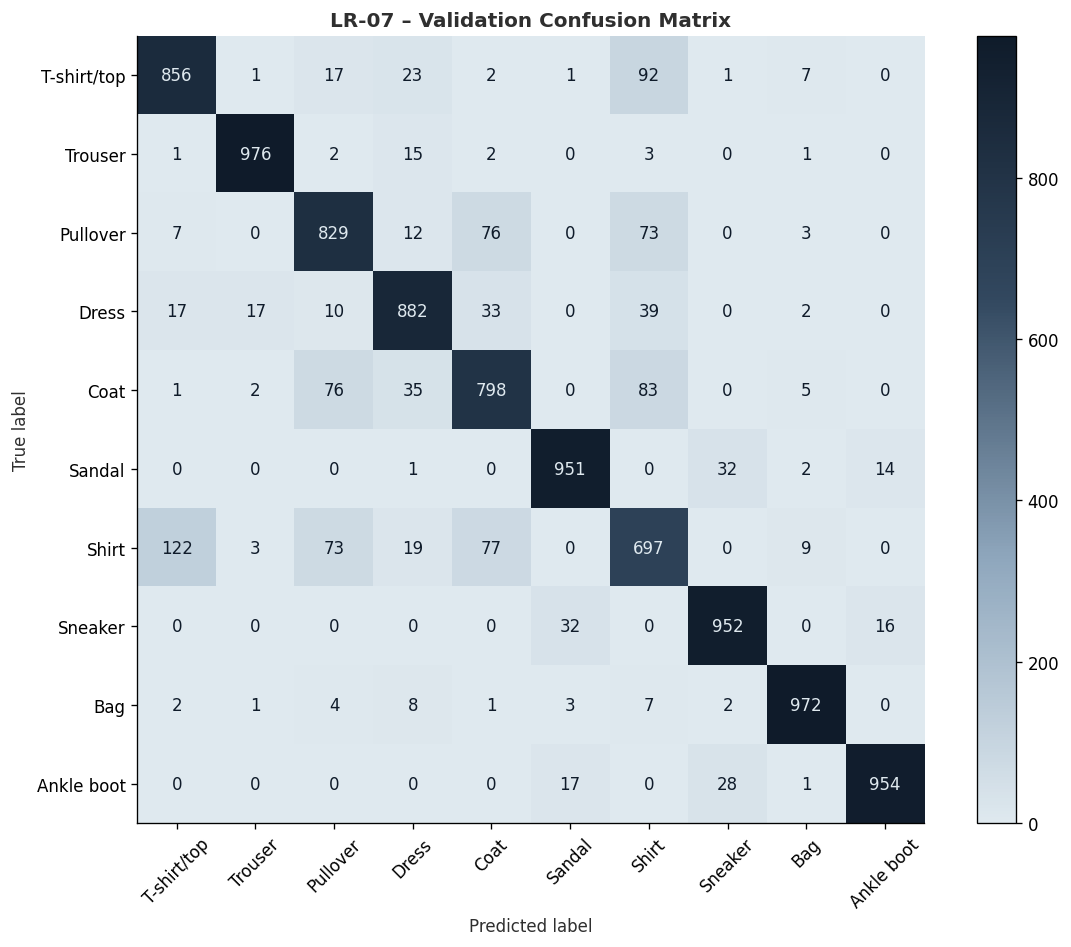

In [66]:
best_cm = plot_confusion_matrix(
    best_experiment,
    "optimized_confusion_matrix.png",
)

In [67]:
best_report = get_classification_report(best_experiment)

best_report.round(4)

,precision,recall,f1-score,support
T-shirt/top,0.8509,0.8560,0.8534,1000.0000
Trouser,0.9760,0.9760,0.9760,1000.0000
Pullover,0.8200,0.8290,0.8245,1000.0000
Dress,0.8864,0.8820,0.8842,1000.0000
Coat,0.8069,0.7980,0.8024,1000.0000
Sandal,0.9472,0.9510,0.9491,1000.0000
Shirt,0.7012,0.6970,0.6991,1000.0000
Sneaker,0.9379,0.9520,0.9449,1000.0000
Bag,0.9701,0.9720,0.9710,1000.0000
Ankle boot,0.9695,0.9540,0.9617,1000.0000


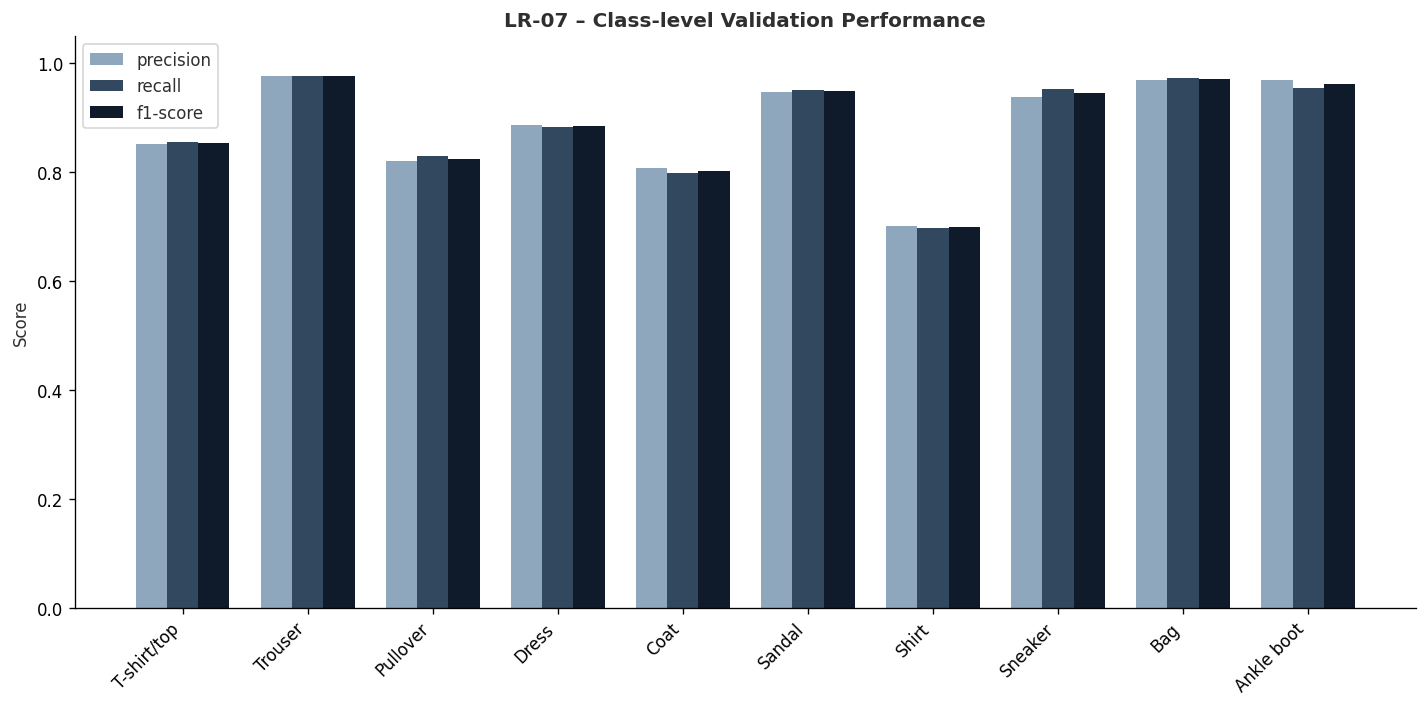

In [68]:
class_metrics = best_report.loc[CLASS_NAMES]

fig, ax = plt.subplots(figsize=(12, 6))

positions = np.arange(len(CLASS_NAMES))
width = 0.25

for offset, metric, color in [
    (-width, "precision", PALETTE["blue_3"]),
    (0, "recall", PALETTE["blue_5"]),
    (width, "f1-score", PALETTE["blue_7"]),
]:
    ax.bar(
        positions + offset,
        class_metrics[metric],
        width,
        label=metric,
        color=color,
    )

ax.set_xticks(
    positions,
    CLASS_NAMES,
    rotation=45,
    ha="right",
)

ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title(f"{best_run_id} – Class-level Validation Performance")
ax.legend()

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "optimized_class_performance.png",
    bbox_inches="tight",
)

plt.show()

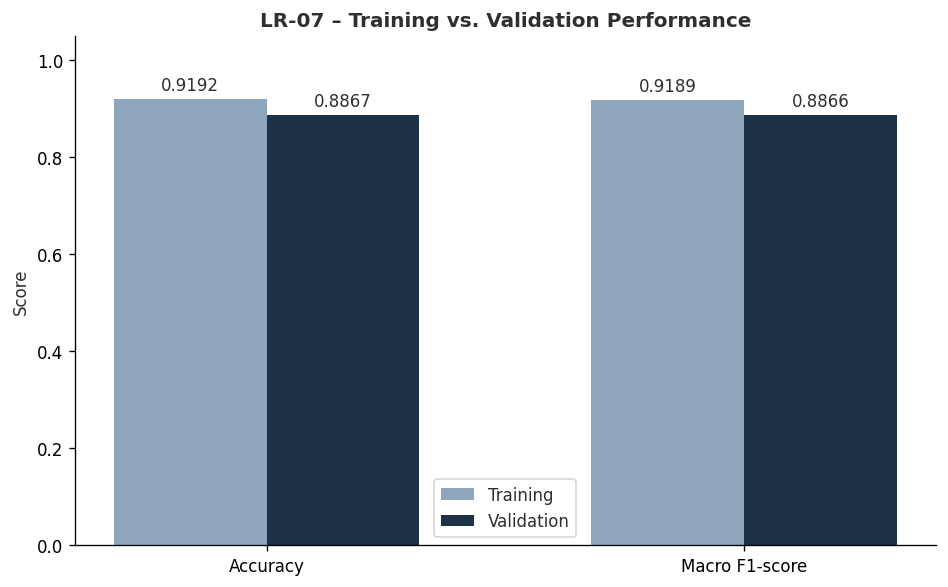

In [69]:
fig, ax = plt.subplots(figsize=(8, 5))

positions = np.arange(2)
width = 0.32

train_values = [
    best_result["train_accuracy"],
    best_result["train_macro_f1"],
]

val_values = [
    best_result["val_accuracy"],
    best_result["val_macro_f1"],
]

train_bars = ax.bar(
    positions - width / 2,
    train_values,
    width,
    label="Training",
    color=PALETTE["blue_3"],
)

val_bars = ax.bar(
    positions + width / 2,
    val_values,
    width,
    label="Validation",
    color=PALETTE["blue_6"],
)

ax.bar_label(train_bars, fmt="%.4f", padding=3)
ax.bar_label(val_bars, fmt="%.4f", padding=3)

ax.set_xticks(
    positions,
    ["Accuracy", "Macro F1-score"],
)

ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title(f"{best_run_id} – Training vs. Validation Performance")
ax.legend()

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "optimized_performance.png",
    bbox_inches="tight",
)

plt.show()

### 7.1. HOG Weight Visualization

A HOG-alapú modell osztályonként 1296 együtthatót tartalmaz. A súlyokat a HOG 6×6-os blokkstruktúrájának megfelelően alakítjuk vissza, majd blokkonként az együtthatók átlagos abszolút értékét jelenítjük meg.

Az ábra a tanult modellsúlyok térbeli eloszlását szemlélteti, nem közvetlen pixelalapú feature importance értékeket.

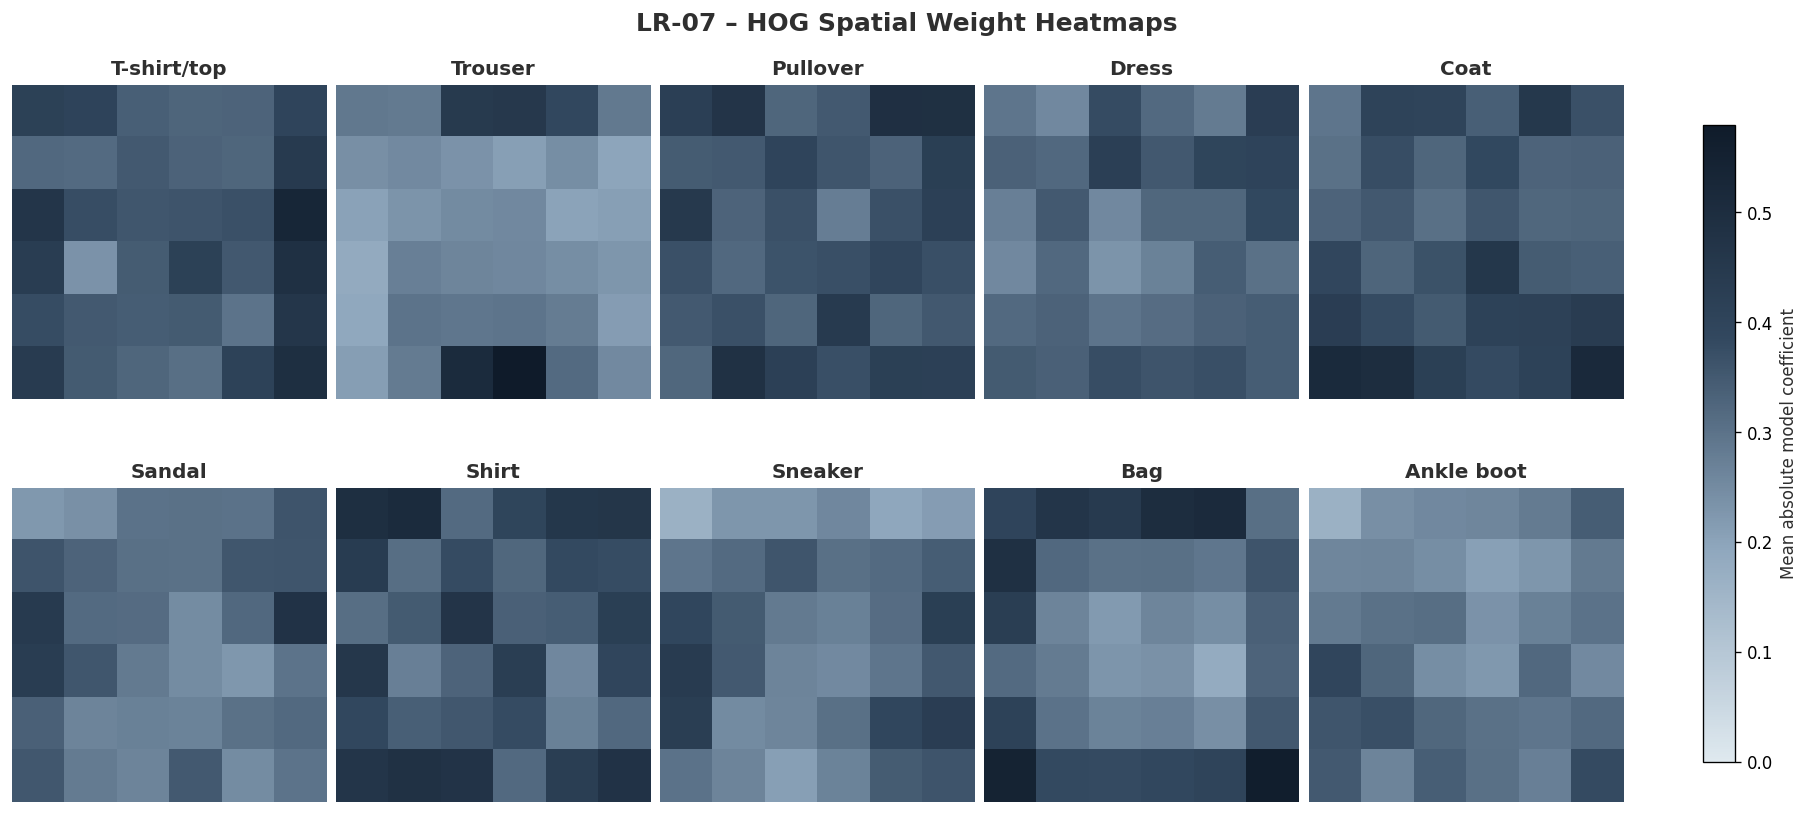

In [ ]:
assert best_config["use_hog"]
assert best_config["pca_components"] is None
assert not best_config["standardize"]
assert best_model.coef_.shape == (10, 1296)

hog_weights = best_model.coef_.reshape(10, 6, 6, 2, 2, 9)

spatial_weights = np.abs(hog_weights).mean(axis=(3, 4, 5))

max_weight = spatial_weights.max()

fig, axes = plt.subplots(
    2,
    5,
    figsize=(15, 7),
    layout="constrained",
)

for class_id, ax in enumerate(axes.flat):
    image = ax.imshow(
        spatial_weights[class_id],
        cmap=BLUE_CMAP,
        vmin=0,
        vmax=max_weight,
        interpolation="nearest",
    )

    ax.set_title(CLASS_NAMES[class_id])
    ax.axis("off")

fig.colorbar(
    image,
    ax=axes.ravel().tolist(),
    shrink=0.8,
    label="Mean absolute model coefficient",
)

fig.suptitle(
    f"{best_run_id} – HOG Spatial Weight Heatmaps",
    fontsize=15,
    fontweight="bold",
)

fig.savefig(
    FIGURES_DIR / "optimized_hog_weight_heatmaps.png",
    bbox_inches="tight",
)

plt.show()

In [72]:
(
    best_eda_report,
    best_total_errors,
    best_selected_errors,
    best_error_share,
) = analyze_eda_confusions(best_cm)

print(f"Total validation errors: {best_total_errors}")
print(f"Selected category-pair errors: {best_selected_errors}")
print(f"Share of total errors: {best_error_share:.2f}%")

best_eda_report.round(4)

Total validation errors: 1133
Selected category-pair errors: 672
Share of total errors: 59.31%


,class_a,class_b,cosine_similarity,misclassifications,share_of_total_errors_pct
0,T-shirt/top,Shirt,0.9489,214,18.8879
1,Pullover,Coat,0.9841,152,13.4157
2,Pullover,Shirt,0.9832,146,12.8861
3,Coat,Shirt,0.9874,160,14.1218


### 7.2. EDA and Misclassification Analysis

A baseline-nál vizsgált kategóriapárok tévesztési gyakoriságának elemzése az optimalizált modellen.

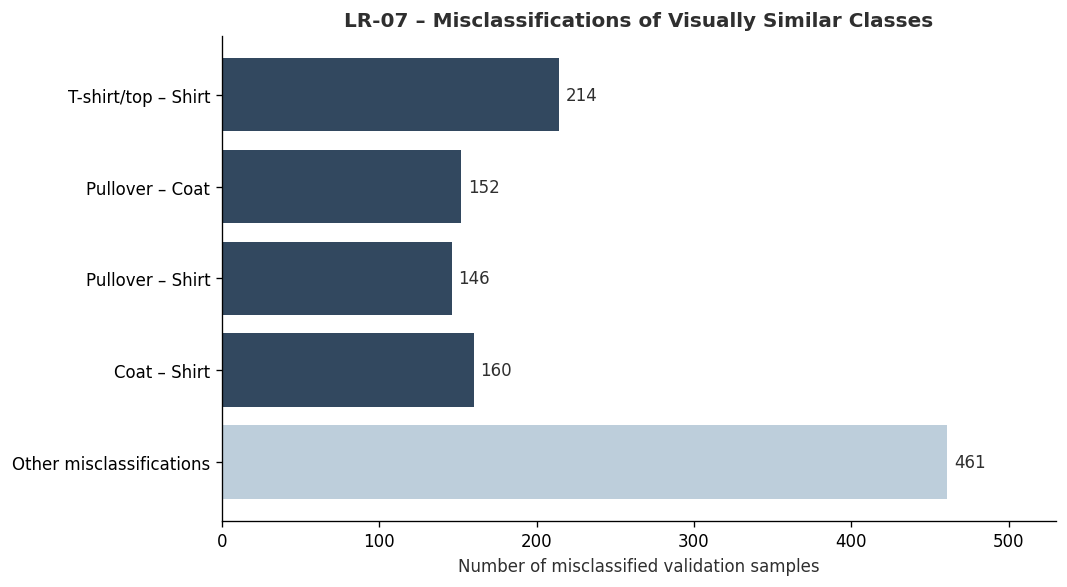

In [73]:
fig, ax = plt.subplots(figsize=(9, 5))

pair_names = (best_eda_report["class_a"] + " – " + best_eda_report["class_b"]).tolist()

error_counts = best_eda_report["misclassifications"].tolist()

pair_names.append("Other misclassifications")

error_counts.append(best_total_errors - best_selected_errors)

bars = ax.barh(
    pair_names,
    error_counts,
    color=[
        PALETTE["blue_5"],
        PALETTE["blue_5"],
        PALETTE["blue_5"],
        PALETTE["blue_5"],
        PALETTE["blue_2"],
    ],
)

ax.bar_label(bars, padding=4)
ax.invert_yaxis()

ax.set_xlim(
    0,
    max(1, max(error_counts)) * 1.15,
)

ax.set_xlabel("Number of misclassified validation samples")

ax.set_title(f"{best_run_id} – Misclassifications of Visually Similar Classes")

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "optimized_eda_error_analysis.png",
    bbox_inches="tight",
)

plt.show()

## 8. Baseline vs. Optimized Comparison

A kísérletek eredményeit a baseline konfigurációhoz viszonyítjuk. A kiválasztott LR-07 modell esetében részletesen összehasonlítjuk a prediktív teljesítményt, a számítási költségeket és az osztályonkénti eredményeket.

In [74]:
comparison = (
    experiment_results.set_index("run_id")
    .loc[
        ["LR-00", best_run_id],
        [
            "train_accuracy",
            "val_accuracy",
            "val_macro_precision",
            "val_macro_recall",
            "val_macro_f1",
            "val_log_loss",
            "accuracy_gap",
            "preprocessing_time_s",
            "training_time_s",
            "total_preprocessing_training_time_s",
            "inference_time_s",
            "n_features",
            "parameter_count",
            "model_size_mib",
            "pipeline_size_mib",
            "n_iter",
        ],
    ]
    .T
)

comparison.columns = ["Baseline", "Optimized"]

comparison["Difference"] = comparison["Optimized"] - comparison["Baseline"]

comparison.round(6)

,Baseline,Optimized,Difference
train_accuracy,0.881900,0.919220,0.037320
val_accuracy,0.861500,0.886700,0.025200
val_macro_precision,0.860849,0.886610,0.025761
val_macro_recall,0.861500,0.886700,0.025200
val_macro_f1,0.861041,0.886636,0.025595
val_log_loss,0.406229,0.309564,-0.096665
accuracy_gap,0.020400,0.032520,0.012120
preprocessing_time_s,2.513707,44.571044,42.057337
training_time_s,68.065178,38.226203,-29.838975
total_preprocessing_training_time_s,70.578885,82.797246,12.218362


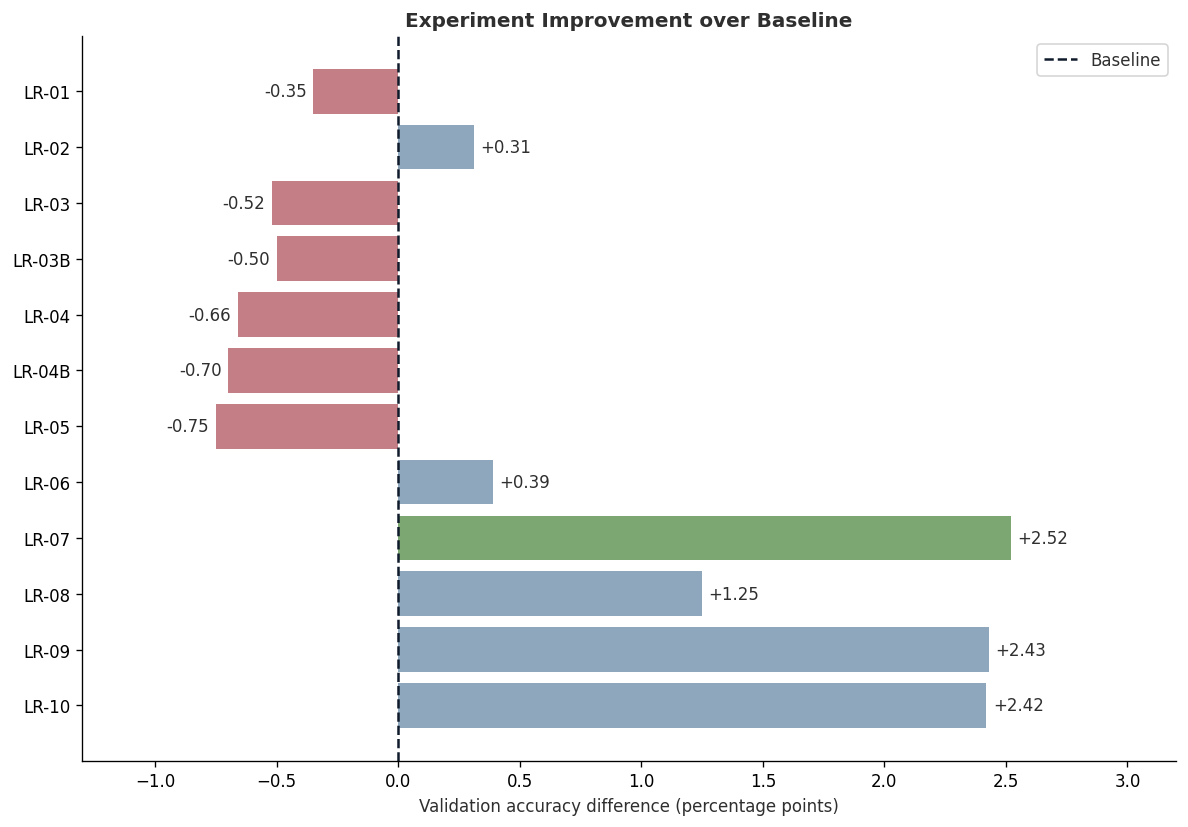

In [75]:
baseline_accuracy = baseline_result["val_accuracy"]

delta_results = (
    experiment_results[experiment_results["run_id"] != "LR-00"].sort_values("run_id").copy()
)

delta_results["accuracy_delta_pp"] = (delta_results["val_accuracy"] - baseline_accuracy) * 100

colors = [
    PALETTE["green_dark"]
    if run_id == best_run_id
    else PALETTE["red_light"]
    if delta < 0
    else PALETTE["blue_3"]
    for run_id, delta in zip(
        delta_results["run_id"],
        delta_results["accuracy_delta_pp"],
    )
]

fig, ax = plt.subplots(figsize=(10, 7))

bars = ax.barh(
    delta_results["run_id"],
    delta_results["accuracy_delta_pp"],
    color=colors,
)

ax.bar_label(bars, fmt="%+.2f", padding=4)

ax.axvline(
    0,
    color=PALETTE["blue_7"],
    linestyle="--",
    label="Baseline",
)

ax.invert_yaxis()
ax.set_xlim(-1.3, 3.2)
ax.set_xlabel("Validation accuracy difference (percentage points)")
ax.set_title("Experiment Improvement over Baseline")
ax.legend()

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "experiment_baseline_comparison.png",
    bbox_inches="tight",
)

plt.show()

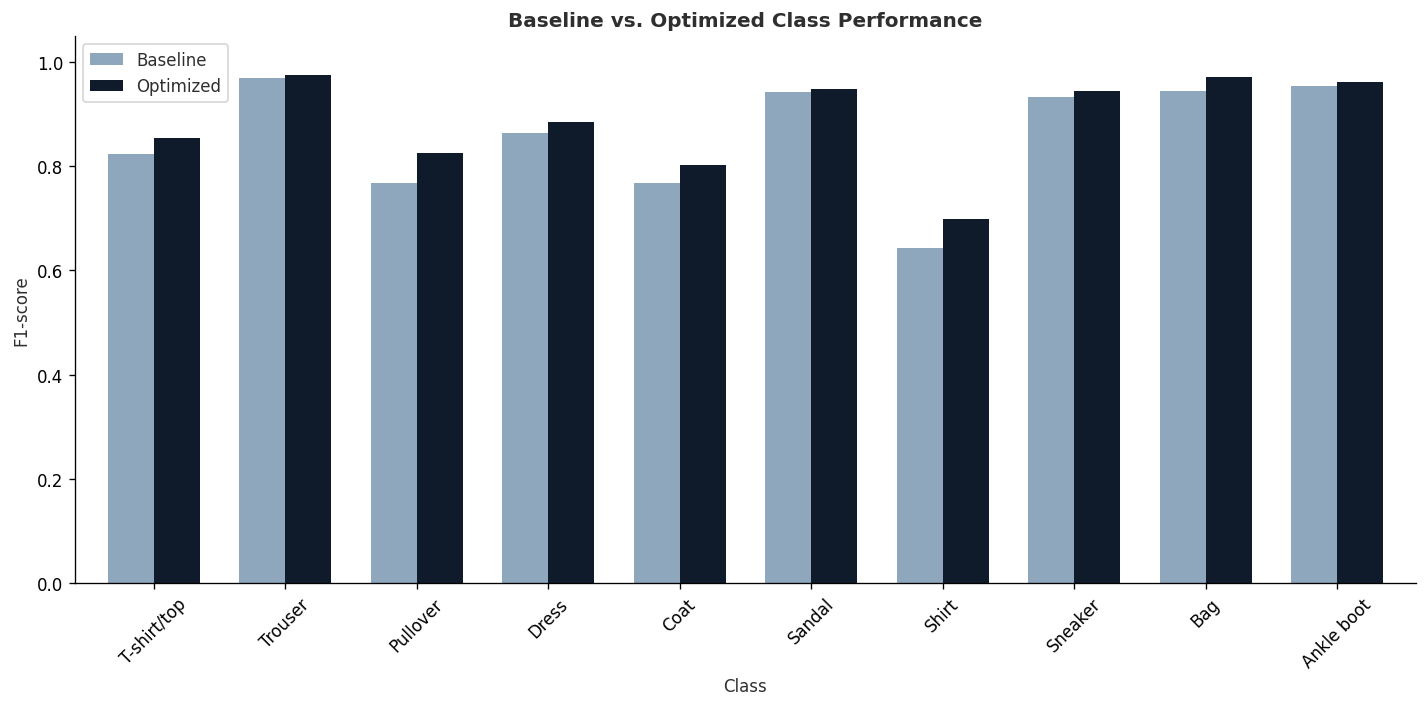

In [76]:
class_comparison = pd.DataFrame(
    {
        "Baseline": baseline_report.loc[CLASS_NAMES, "f1-score"],
        "Optimized": best_report.loc[CLASS_NAMES, "f1-score"],
    }
)

fig, ax = plt.subplots(figsize=(12, 6))

class_comparison.plot(
    kind="bar",
    ax=ax,
    color=[
        PALETTE["blue_3"],
        PALETTE["blue_7"],
    ],
    width=0.7,
    rot=45,
)

ax.set_ylim(0, 1.05)
ax.set_xlabel("Class")
ax.set_ylabel("F1-score")
ax.set_title("Baseline vs. Optimized Class Performance")

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "class_performance_comparison.png",
    bbox_inches="tight",
)

plt.show()

### 8.1. Comparison Observations

- Az LR-07 konfiguráció 88,67%-os validation accuracyt és 88,66%-os macro F1-score-t ért el, ami 2,52 százalékpontos accuracy javulást jelent a baseline-hoz képest.
- A validációs hibák száma 1385-ről 1133-ra csökkent.
- A HOG reprezentáció különösen a nehezebben elkülöníthető felsőruházati kategóriák osztályozását javította. A Shirt továbbra is a legnehezebben osztályozható kategória.
- Az EDA során azonosított négy kategóriapár közötti tévesztések száma 788-ról 672-re csökkent. Az optimalizált modell hibáinak 59,31%-a továbbra is ezekhez a kategóriapárokhoz kapcsolódik.
- A modell tanítási ideje 68,07-ről 38,23 másodpercre csökkent, azonban a HOG jellemzőkinyerés miatt nőtt a teljes előfeldolgozási és tanítási idő.
- A jobb prediktív teljesítmény nagyobb jellemzőszámmal és előfeldolgozási többletköltséggel jár, miközben a modell tárolási igénye továbbra is alacsony.

## 9. Final Results Export

A baseline és a kiválasztott optimalizált modell összesített és osztályonkénti eredményeinek exportálása a közös modellösszehasonlításhoz.

A mentett metrikák a training és validation halmazokon mért eredményeket tartalmazzák. A hivatalos teszthalmaz értékelése a projekt végső összehasonlítási szakaszában történik.

In [77]:
final_metrics = experiment_results.set_index("run_id").loc[["LR-00", best_run_id]].reset_index()

final_metrics.insert(
    1,
    "model_variant",
    ["baseline", "optimized"],
)

final_metrics.to_csv(
    FINAL_METRICS_PATH,
    index=False,
)

print(f"Final metrics saved: {FINAL_METRICS_PATH}")

final_metrics[
    [
        "run_id",
        "model_variant",
        "train_accuracy",
        "val_accuracy",
        "val_macro_f1",
        "val_log_loss",
        "training_time_s",
        "model_size_mib",
    ]
].round(6)

Final metrics saved: c:\Users\aszen\Desktop\ÓBUDAI MSC\03_2026-2027-1\03_DL\00_Feleves feladat\KÓDOK\DLProject_FashionMNIST\results\experiments\logistic_regression_final_metrics.csv


,run_id,model_variant,train_accuracy,val_accuracy,val_macro_f1,val_log_loss,training_time_s,model_size_mib
0,LR-00,baseline,0.88190,0.8615,0.861041,0.406229,68.065178,0.060767
1,LR-07,optimized,0.91922,0.8867,0.886636,0.309564,38.226203,0.099830


In [78]:
classification_results = []

for variant, run_id, report in [
    ("baseline", "LR-00", baseline_report),
    ("optimized", best_run_id, best_report),
]:
    class_report = report.loc[CLASS_NAMES].copy()

    class_report.index.name = "class"
    class_report = class_report.reset_index()

    class_report.insert(0, "run_id", run_id)
    class_report.insert(1, "model_variant", variant)
    class_report.insert(2, "split", "validation")

    classification_results.append(class_report)

classification_results = pd.concat(
    classification_results,
    ignore_index=True,
)

classification_results.to_csv(
    CLASSIFICATION_REPORT_PATH,
    index=False,
)

print(f"Classification report saved: {CLASSIFICATION_REPORT_PATH}")

classification_results.round(6)

Classification report saved: c:\Users\aszen\Desktop\ÓBUDAI MSC\03_2026-2027-1\03_DL\00_Feleves feladat\KÓDOK\DLProject_FashionMNIST\results\experiments\logistic_regression_classification_report.csv


,run_id,model_variant,split,class,precision,recall,f1-score,support
0,LR-00,baseline,validation,T-shirt/top,0.803996,0.845,0.823988,1000.0
1,LR-00,baseline,validation,Trouser,0.974747,0.965,0.969849,1000.0
2,LR-00,baseline,validation,Pullover,0.768769,0.768,0.768384,1000.0
3,LR-00,baseline,validation,Dress,0.868687,0.860,0.864322,1000.0
4,LR-00,baseline,validation,Coat,0.759531,0.777,0.768166,1000.0
5,LR-00,baseline,validation,Sandal,0.944835,0.942,0.943415,1000.0
6,LR-00,baseline,validation,Shirt,0.664179,0.623,0.642931,1000.0
7,LR-00,baseline,validation,Sneaker,0.929494,0.936,0.932735,1000.0
8,LR-00,baseline,validation,Bag,0.943057,0.944,0.943528,1000.0
9,LR-00,baseline,validation,Ankle boot,0.951195,0.955,0.953094,1000.0


## 10. Conclusions

A 13 dokumentált kísérlet közül az LR-07 konfiguráció biztosította a legjobb validációs teljesítményt.

A főbb megállapítások:

- A nyers pixelreprezentáció esetében a C=0.1 regularizációs konfiguráció teljesített a legjobban.
- A standardizálás nem javította a validációs teljesítményt.
- A 187 komponenses PCA kedvező pontosság–tanítási idő kompromisszumot biztosított.
- A HOG jellemzőkinyerés eredményezte a legnagyobb pontosságjavulást.
- Az optimalizált modell validation accuracyje 86,15%-ról 88,67%-ra nőtt, nagyobb előfeldolgozási költség mellett.
- A modell tárolási igénye továbbra is alacsony.

A baseline és az optimalizált modell, valamint a hozzájuk tartozó preprocessing pipeline rendelkezésre áll a projekt végső modellösszehasonlításához.

A következtetések egyetlen adatfelosztás és random seed alapján születtek.